# Estimated-segment coefficient Gram study

Use the coefficient Gram matrix **directly**, divided by full-data n=1692 or
p=110. No mixtures, trace matching, eigenvalue clipping or artificial jitter.
Only slope coefficients enter B; fitted intercepts do not enter the Gram.
The distinction between /n and /p is explicit: they differ by n/p≈15.38.

Delta=1,2,5; both intercept choices; LS or logistic auxiliary loss. Unpenalized
posterior logistic fits: FISTA/L-BFGS/GD, budgets8,16,20,30,50,100. Unpenalized
LS auxiliary fits are exact (not artificially stopped). Penalized fits: matched
L1 or L2 family and strength1e-8,1e-6,1e-5,1e-4,1e-3. Squared loss is residual²,
logistic is log(1+exp(z))-yz; both are weighted means plus the declared penalty.
Intercepts are unpenalized. Logistic/logistic uses the identical fit in both
stages; LS/logistic matches penalty family and numerical strength, not loss.
Convergence-seeking penalized fits report KKT diagnostics; finite budgets apply
only to the unpenalized logistic cases. No raw coefficients are assumed noiseless.

336 model settings × two Gram divisors = **672 comparisons**. Screening uses
512 draws/seed123; finalists use 1024 draws with seeds123 and42. Select the best20
conditional shapes plus leaders within loss/penalty/divisor groups for checks;
rank checked results by mean TV to the earlier rank3 target, without a P(1) cutoff.
36 jobs. Every failure or undefined Gram is reported; no silent repair. State
equations remain heuristic for finite/penalized fits and plug-in Gram estimates.
Numerical checks are not confidence intervals or statistical calibration.

First select a pilot split using the original auxiliary fits and auxiliary loss.
Then fit that same loss/penalty/solver separately on the two **estimated** segments
with unit within-segment weights. Stack those slope vectors into Bseg and divide
Bseg-transpose-Bseg by full-data n or p. Retain the global feature transformation;
do not rewhiten within segments. No true split is supplied. If the pilot selects
zero changes, the segment Gram is undefined and the case is reported as such.
Posterior regression fits and prior remain those of the paired whole-data study;
only the covariance estimator changes. A paired all-configuration comparison
with whole-data Gram follows the top20 figures.


In [1]:
"""Paired whole-data and estimated-segment coefficient Gram experiments."""
from tools.myocardial_final_redo import *
from tools.myocardial_direct_moment_experiment import state_at
from tools.myocardial_best_ones import curve_metrics
from WERM.myocardial_finite_intercept import finite_intercept_column
from WERM.myocardial_no_intercept_solvers import fit_column
from WERM.myocardial_intercept import fit_with_intercept,intercept_loglikelihood
from tools.myocardial_matched_l2_fine import solve_logistic_l2

BASE=Path('results/myocardial_final_redo_e3d965cc4b9b')


def configurations():
    specs=[]
    for d in (1,2,5):
        for intercept in (False,True):
            for aux in ('squared','logistic'):
                for method in ('fista','lbfgs','gd'):
                    for budget in (8,16,20,30,50,100):
                        specs.append(dict(Delta=d,intercept=intercept,aux_loss=aux,
                            penalty='none',strength=0.,method=method,budget=budget))
                for penalty in ('l1','l2'):
                    for strength in (1e-8,1e-6,1e-5,1e-4,1e-3):
                        specs.append(dict(Delta=d,intercept=intercept,aux_loss=aux,
                            penalty=penalty,strength=strength,method='full',budget=0))
    for i,s in enumerate(specs):s['id']=f'config{i:03d}'
    return specs


def column(X,y,w,spec,loss):
    n,p=X.shape;intercept=spec['intercept'];family=spec['penalty'];strength=spec['strength']
    if loss=='logistic' and family=='none':
        if intercept:return finite_intercept_column(X,y,w,spec['method'],spec['budget'])
        return fit_column(X,y,w,spec['method'],spec['budget'])
    if loss=='logistic' and family=='l2' and not intercept:
        r=solve_logistic_l2(X,y,w,strength);return dict(r,intercept=0.)
    if loss=='logistic' and intercept:
        r=fit_with_intercept(X,y,np.array([w]),family,strength)
        return dict(coef=r['coef'][:,0],intercept=float(r['intercepts'][0]),**r['checks'][0])
    design=np.column_stack([X,np.ones(n)]) if intercept else X
    r=fit_weighted(design,y,sample_weight=w,loss=loss,loss_scale=2. if loss=='squared' else 1.,
        penalty=family,penalty_strength=strength,unpenalized_indices=[p] if intercept else [],
        max_iter=30000,tol=1e-8)
    return dict(coef=r.coef[:p],intercept=float(r.coef[p]) if intercept else 0.,
                kkt=r.kkt_violation,success=r.converged,iterations=r.n_iter)


def fit(X,y,phi,spec,loss):
    cols=[column(X,y,w,spec,loss) for w in phi]
    B=np.column_stack([c['coef'] for c in cols]);alpha=np.array([c.get('intercept',0.) for c in cols])
    theta=X@B+alpha;adjusted,b=empirical_adjustment(theta,y,phi,len(y)/X.shape[1],loss=loss)
    V=adjusted-(X.mean(axis=0)@B+alpha) if spec['intercept'] else adjusted
    return dict(coef=B,theta=theta,V=V,b=b,intercepts=alpha,checks=cols)


def prepare(spec,X,y,locations,root):
    path=root/(spec['id']+'_fits.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    try:
        d=spec['Delta'];eta,prior,phi=configuration_prior(len(y),locations[(locations>=d)&(locations<=len(y)-d)])
        auxiliary=fit(X,y,phi,spec,spec['aux_loss'])
        posterior=auxiliary if spec['aux_loss']=='logistic' else fit(X,y,phi,spec,'logistic')
        e,psi=pilot(auxiliary['theta'],y,eta,spec['aux_loss'])
        result=dict(spec=spec,setting=dict(eta=eta,prior=prior,phi=phi),auxiliary=auxiliary,
            posterior=posterior,pilot=e,psi=psi,loss=spec['aux_loss'],delta=len(y)/X.shape[1],rate=float(y.mean()))
    except Exception:result=dict(error=traceback.format_exc(),spec=spec)
    atomic_save(path,result);return result


def balanced_segment_weights(y):
    y=np.asarray(y)
    if not np.all(np.isin(y,[0,1])) or len(np.unique(y))!=2:
        raise ValueError('Balanced segment requires both binary classes')
    counts=np.bincount(y.astype(int),minlength=2)
    return len(y)/(2*counts[y.astype(int)])


def gram_coefficients(prepared,X,y,mode,root):
    if mode=='whole':return prepared['auxiliary']['coef']
    path=root/(prepared['spec']['id']+'_segment_coefficients.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    e=prepared['pilot']
    if not 0<e<len(y):raise ValueError('No pilot change point: segment Gram undefined')
    spec=prepared['spec'];columns=[]
    for segment in (slice(None,e),slice(e,None)):
        Xi,yi=X[segment],y[segment]
        w=balanced_segment_weights(yi) if mode=='segmented_balanced' else np.ones(len(yi))
        c=column(Xi,yi,w,spec,spec['aux_loss']);columns.append(c)
    B=np.column_stack([c['coef'] for c in columns])
    atomic_save(path,B);atomic_save(root/(spec['id']+'_segment_checks.pkl'),columns)
    return B


def evaluate(prepared,X,y,ages,mode,denominator,root,power=9,seed=123):
    ident=prepared['spec']['id']+'_'+denominator
    path=root/f'{ident}_p{power}s{seed}.pkl'
    if path.exists():return pickle.load(path.open('rb'))
    partial=root/f'{ident}_p{power}s{seed}_partial.pkl'
    try:
        spec=prepared['spec'];B=gram_coefficients(prepared,X,y,mode,root)
        divisor=len(y) if denominator=='n' else X.shape[1]
        rho=B.T@B/divisor;eigenvalues=np.linalg.eigvalsh(rho)
        if eigenvalues.min()<=0 or eigenvalues.min()<1e-12*eigenvalues.max():
            raise ValueError('Singular/numerically rank-deficient Gram: no jitter, clipping or repair applied')
        states=pickle.load(partial.open('rb')) if partial.exists() else []
        eta=prepared['setting']['eta'];n=len(y)
        for e in eta[len(states):]:
            psi=np.zeros(n,int) if e<0 else (np.arange(n)>=e).astype(int)
            states.append(state_at(prepared,rho,psi,power=power,seed=seed,loss='logistic'))
            if len(states)%8==0:atomic_save(partial,states)
        atomic_save(partial,states);values=[]
        for e,state in zip(eta,states):
            psi=np.zeros(n,int) if e<0 else (np.arange(n)>=e).astype(int)
            if spec['intercept']:ll=intercept_loglikelihood(prepared['posterior']['V'],y,rho,state,psi,order=160)
            else:ll=gaussian_logistic_loglikelihood(prepared['posterior']['V'],y,rho,state['lambda'],state['kappa'],psi,quadrature_order=160)
            values.append(ll)
        result=normalize_posterior(values,prepared['setting']['prior']);a=ages[eta[1:]]
        target=pickle.load((BASE/'scenario_100_100_q10_seed123.pkl').open('rb'))
        metrics=curve_metrics(a,result['conditional'],dict(zip(target['ages'],target['conditional'])))
        result.update(spec,id=ident,mode=mode,denominator=denominator,rho=rho,ages=a,
            pilot=prepared['pilot'],pilot_age=ages[prepared['pilot']] if prepared['pilot']>=0 else np.nan,
            P_1=result['presence'],TV_to_rank3=metrics['TV'],peak_age=metrics['peak'],mass_above55=metrics['above55'],
            correlation=rho[0,1]/np.sqrt(rho[0,0]*rho[1,1]),rho_11=rho[0,0],rho_12=rho[0,1],rho_22=rho[1,1],
            max_state_residual=max(s['training_residual'] for s in states),power=power,seed=seed,checkpoint=str(path),
            max_aux_kkt=max(c.get('kkt',np.nan) for c in prepared['auxiliary']['checks']),
            max_post_kkt=max(c.get('kkt',np.nan) for c in prepared['posterior']['checks']))
    except Exception:result=dict(error=traceback.format_exc(),id=ident,spec=prepared['spec'],mode=mode,power=power,seed=seed)
    atomic_save(path,result);return result


def table(rows):
    return pd.DataFrame([{k:v for k,v in r.items() if k not in ('rho','ages','conditional','probabilities','log_likelihood')}
        for r in rows if 'error' not in r])


def run(mode='whole',smoke=False):
    if mode not in ('whole','segmented','segmented_balanced'):raise ValueError(mode)
    X,y,ages,locations=load_data();specs=configurations()
    fingerprint=hashlib.sha256(Path('tools/myocardial_gram_comparison.py').read_bytes()).hexdigest()[:12]
    shared=Path('results')/('myocardial_gram_pair_'+fingerprint);shared.mkdir(exist_ok=True)
    root=shared/mode;root.mkdir(exist_ok=True)
    (shared/'specification.json').write_text(json.dumps(dict(configurations=specs,normalizations=['n','p'],
        primary_draws=512,final_draws=1024,final_seeds=[123,42],coefficient_gram='slopes only, intercept excluded',
        segmented='same pilot auxiliary loss, solver, penalty; full-data n or p divisor, no segment rewhitening',
        penalty_matching='same family and strength in auxiliary and posterior; squared loss scale=2'),indent=2))
    if smoke:
        chosen=[dict(specs[0],id='smoke_ls'),dict(next(s for s in specs if s['aux_loss']=='logistic' and s['intercept']),id='smoke_logistic')]
        for spec in chosen:
            p=prepare(spec,X,y,locations,shared)
            assert 'error' not in p,p
            B=gram_coefficients(p,X,y,mode,root)
            assert B.shape==(X.shape[1],2)
            for denom in ('n','p'):assert np.linalg.eigvalsh(B.T@B/(len(y) if denom=='n' else X.shape[1])).min()>0
        print('Gram fit and',mode,'segment checks passed; configurations:',len(specs)*2,flush=True);return root
    with parallel_config(backend='loky',inner_max_num_threads=1):
        prepared=Parallel(n_jobs=36)(delayed(prepare)(s,X,y,locations,shared) for s in specs)
        # Segment coefficients are populated once per setting before the two
        # normalization tasks, preventing competing writes to their checkpoint.
    errors=[p for p in prepared if 'error' in p]
    valid=[]
    for p in prepared:
        if 'error' in p:continue
        if mode!='whole':
            try:gram_coefficients(p,X,y,mode,root)
            except Exception:
                errors.append(dict(id=p['spec']['id'],error=traceback.format_exc()));continue
        valid.append(p)
    with parallel_config(backend='loky',inner_max_num_threads=1):
        results=Parallel(n_jobs=36)(delayed(evaluate)(p,X,y,ages,mode,d,root) for p in valid for d in ('n','p'))
    errors += [r for r in results if 'error' in r]
    summary=table(results);summary.to_csv(root/'summary.csv',index=False)
    selected=pd.concat([summary.sort_values('TV_to_rank3').head(20),
        summary.sort_values('TV_to_rank3').groupby(['aux_loss','penalty','denominator']).head(2)]).drop_duplicates('id')
    selected.to_csv(root/'selected_for_validation.csv',index=False)
    mapping={p['spec']['id']:p for p in valid}
    with parallel_config(backend='loky',inner_max_num_threads=1):
        checked=Parallel(n_jobs=36)(delayed(evaluate)(mapping[row.id.rsplit('_',1)[0]],X,y,ages,mode,row.denominator,root,10,seed)
            for row in selected.itertuples() for seed in (123,42))
    errors += [r for r in checked if 'error' in r];table(checked).to_csv(root/'validation.csv',index=False)
    ranked=[]
    for ident in selected.id:
        pair=[r for r in checked if r['id']==ident and 'error' not in r]
        if len(pair)!=2:continue
        a,b=pair;row=table([a]).iloc[0].to_dict()
        row.update(mean_TV_to_rank3=(a['TV_to_rank3']+b['TV_to_rank3'])/2,P1_min=min(a['P_1'],b['P_1']),
            P1_max=max(a['P_1'],b['P_1']),numerical_TV=.5*np.abs(a['conditional']-b['conditional']).sum(),check_checkpoint=b['checkpoint'])
        ranked.append(row)
    ranked=pd.DataFrame(ranked).sort_values('mean_TV_to_rank3');ranked.insert(0,'rank',np.arange(1,len(ranked)+1))
    ranked.to_csv(root/'ranked.csv',index=False);ranked.head(20).to_csv(root/'top_twenty.csv',index=False)
    (root/'errors.json').write_text(json.dumps(errors,indent=2,default=str))
    if mode!='whole' and (shared/'whole'/'summary.csv').exists():
        whole=pd.read_csv(shared/'whole'/'summary.csv')
        summary.merge(whole,on='id',suffixes=('_segmented','_whole')).to_csv(root/'paired_whole_vs_segmented.csv',index=False)
    print('GRAM STUDY COMPLETE',mode,root,flush=True);return root




/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
root=run('segmented')
print(root)

GRAM STUDY COMPLETE segmented results/myocardial_gram_pair_1ce06b10b4f5/segmented


results/myocardial_gram_pair_1ce06b10b4f5/segmented


All tested outcomes:


,presence,absence,Delta,intercept,aux_loss,penalty,strength,method,budget,id,...,correlation,rho_11,rho_12,rho_22,max_state_residual,power,seed,checkpoint,max_aux_kkt,max_post_kkt
0,1.000000,0.000000e+00,1,False,squared,none,0.00000,fista,8,config000_n,...,-0.000184,82.127996,-0.030052,325.294470,8.358104e-03,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,3.076424e-18,2.052392e-04
1,1.000000,0.000000e+00,1,False,squared,none,0.00000,fista,8,config000_p,...,-0.000184,1263.277906,-0.462261,5003.620400,8.698221e-02,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,3.076424e-18,2.052392e-04
2,1.000000,0.000000e+00,1,False,squared,none,0.00000,fista,16,config001_n,...,-0.000184,82.127996,-0.030052,325.294470,8.358104e-03,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,3.076424e-18,1.901676e-04
3,1.000000,0.000000e+00,1,False,squared,none,0.00000,fista,16,config001_p,...,-0.000184,1263.277906,-0.462261,5003.620400,8.698221e-02,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,3.076424e-18,1.901676e-04
4,1.000000,0.000000e+00,1,False,squared,none,0.00000,fista,20,config002_n,...,-0.000184,82.127996,-0.030052,325.294470,8.358104e-03,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,3.076424e-18,1.803467e-04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
667,1.000000,0.000000e+00,5,True,logistic,l2,0.00001,full,0,config333_p,...,0.282617,18.083187,4.485238,13.928327,2.259463e-10,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,2.982834e-09,2.982834e-09
668,1.000000,3.284371e-13,5,True,logistic,l2,0.00010,full,0,config334_n,...,0.397644,0.120219,0.046207,0.112320,6.445802e-10,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,3.865134e-11,3.865134e-11
669,1.000000,5.432213e-57,5,True,logistic,l2,0.00010,full,0,config334_p,...,0.397644,1.849182,0.710751,1.727693,6.543424e-12,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,3.865134e-11,3.865134e-11
670,0.519200,4.807998e-01,5,True,logistic,l2,0.00100,full,0,config335_n,...,0.358144,0.002423,0.000953,0.002921,7.014027e-10,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,1.229152e-09,1.229152e-09


Top20:


rank,presence,absence,Delta,intercept,aux_loss,penalty,strength,method,budget,id,mode,denominator,pilot,pilot_age,P_1,TV_to_rank3,peak_age,mass_above55,correlation,rho_11,rho_12,rho_22,max_state_residual,power,seed,checkpoint,max_aux_kkt,max_post_kkt,mean_TV_to_rank3,P1_min,P1_max,numerical_TV,check_checkpoint
1,0.25232,0.74768,2,True,squared,l1,0.00010,full,0,config189_n,segmented,n,1127,67.00000,0.25232,0.24181,81.00000,0.99265,0.29495,0.04117,0.01145,0.03660,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config189_n_p10s123.pkl,0.00000,0.00000,0.24081,0.25232,0.26107,0.01754,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config189_n_p10s42.pkl
2,0.24799,0.75201,1,True,squared,l1,0.00010,full,0,config077_n,segmented,n,1127,67.00000,0.24799,0.24338,81.00000,0.99044,0.29495,0.04117,0.01145,0.03660,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config077_n_p10s123.pkl,0.00000,0.00000,0.24255,0.24799,0.25663,0.01775,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config077_n_p10s42.pkl
3,0.24637,0.75363,5,True,squared,l1,0.00010,full,0,config301_n,segmented,n,1127,67.00000,0.24637,0.24214,81.00000,0.99560,0.29495,0.04117,0.01145,0.03660,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config301_n_p10s123.pkl,0.00000,0.00000,0.24381,0.24637,0.25602,0.01720,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config301_n_p10s42.pkl
4,0.28359,0.71641,5,False,squared,l1,0.00100,full,0,config246_n,segmented,n,924,64.00000,0.28359,0.32956,79.00000,1.00000,0.26678,0.00513,0.00228,0.01428,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config246_n_p10s123.pkl,0.00000,0.00000,0.32273,0.27184,0.28359,0.01900,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config246_n_p10s42.pkl
5,0.28723,0.71277,2,False,squared,l1,0.00100,full,0,config134_n,segmented,n,924,64.00000,0.28723,0.32915,79.00000,1.00000,0.26678,0.00513,0.00228,0.01428,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config134_n_p10s123.pkl,0.00000,0.00000,0.32334,0.27680,0.28723,0.01850,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config134_n_p10s42.pkl
6,0.28363,0.71637,1,False,squared,l1,0.00100,full,0,config022_n,segmented,n,924,64.00000,0.28363,0.32909,79.00000,1.00000,0.26678,0.00513,0.00228,0.01428,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config022_n_p10s123.pkl,0.00000,0.00000,0.32340,0.27349,0.28363,0.01813,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config022_n_p10s42.pkl
7,0.13173,0.86827,5,True,squared,l2,0.00001,full,0,config305_n,segmented,n,1127,67.00000,0.13173,0.34857,86.00000,0.99442,0.27689,0.04806,0.01265,0.04345,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config305_n_p10s123.pkl,0.00000,0.00000,0.34374,0.13173,0.13589,0.01331,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config305_n_p10s42.pkl
8,0.14673,0.85327,2,True,squared,l2,0.00001,full,0,config193_n,segmented,n,1127,67.00000,0.14673,0.37385,86.00000,0.99100,0.27689,0.04806,0.01265,0.04345,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config193_n_p10s123.pkl,0.00000,0.00000,0.36821,0.14673,0.15059,0.01365,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config193_n_p10s42.pkl
9,0.14363,0.85637,1,True,squared,l2,0.00001,full,0,config081_n,segmented,n,1127,67.00000,0.14363,0.37872,86.00000,0.98799,0.27689,0.04806,0.01265,0.04345,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config081_n_p10s123.pkl,0.00000,0.00000,0.37345,0.14363,0.14752,0.01439,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config081_n_p10s42.pkl
10,0.97338,0.02662,1,False,squared,l1,0.00100,full,0,config022_p,segmented,p,924,64.00000,0.97338,0.52493,79.00000,1.00000,0.26678,0.07884,0.03511,0.21970,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config022_p_p10s123.pkl,0.00000,0.00000,0.51511,0.96778,0.97338,0.02397,results/myocardial_gram_pair_1ce06b10b4f5/segmented/config022_p_p10s42.pkl


Errors/non-evaluable settings:


[]

### #1: config189_n

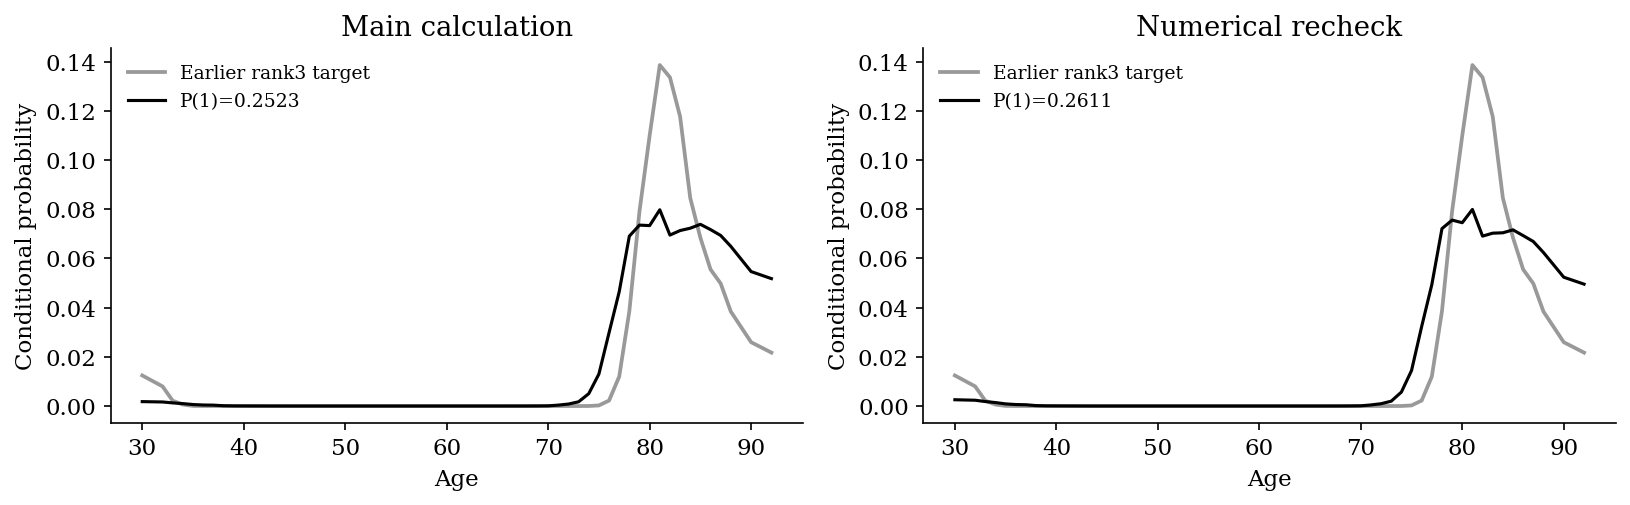

### #2: config077_n

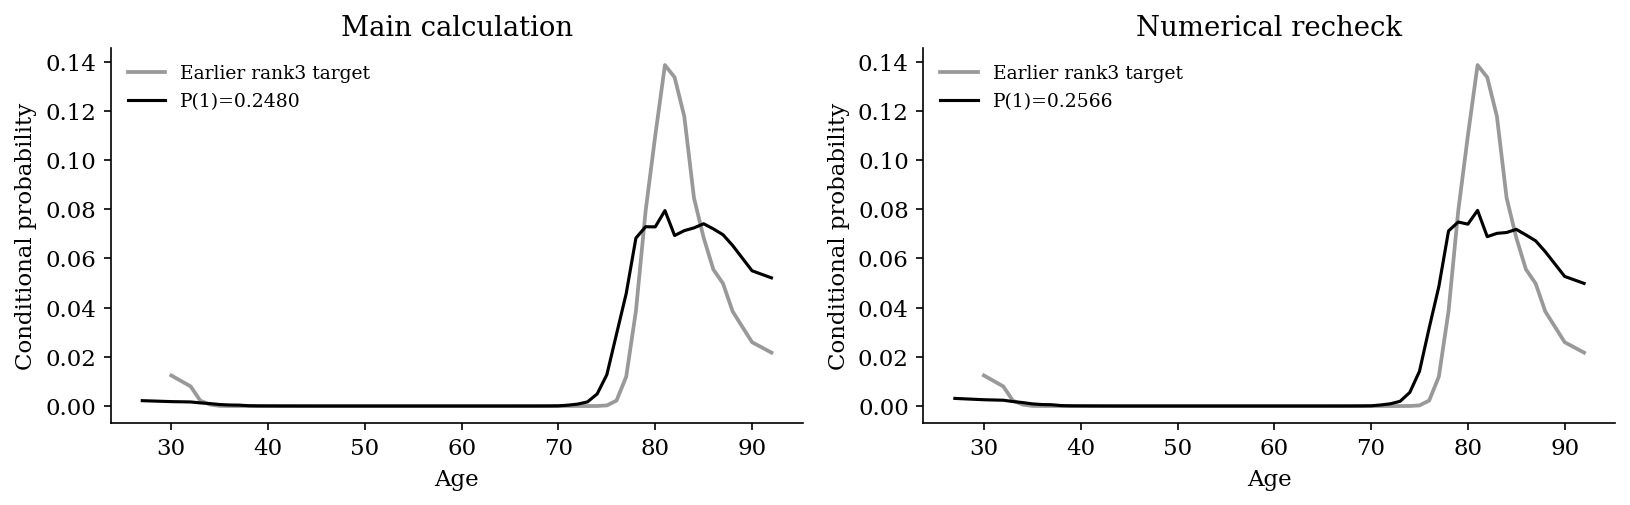

### #3: config301_n

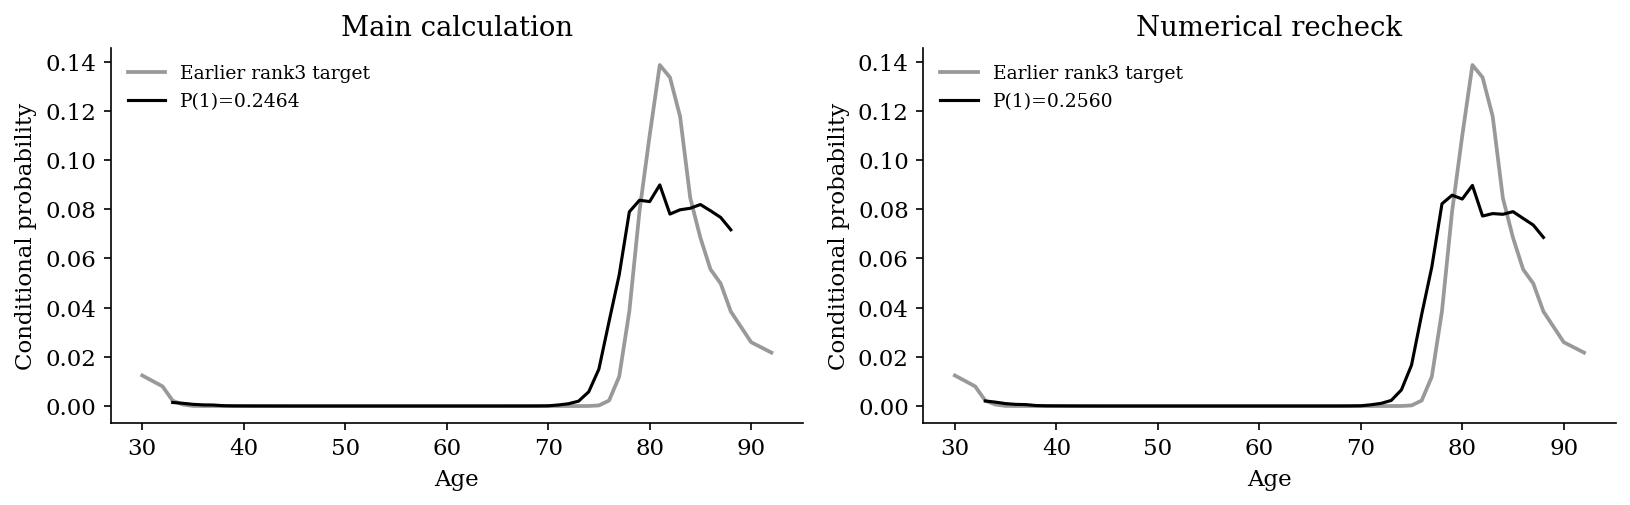

### #4: config246_n

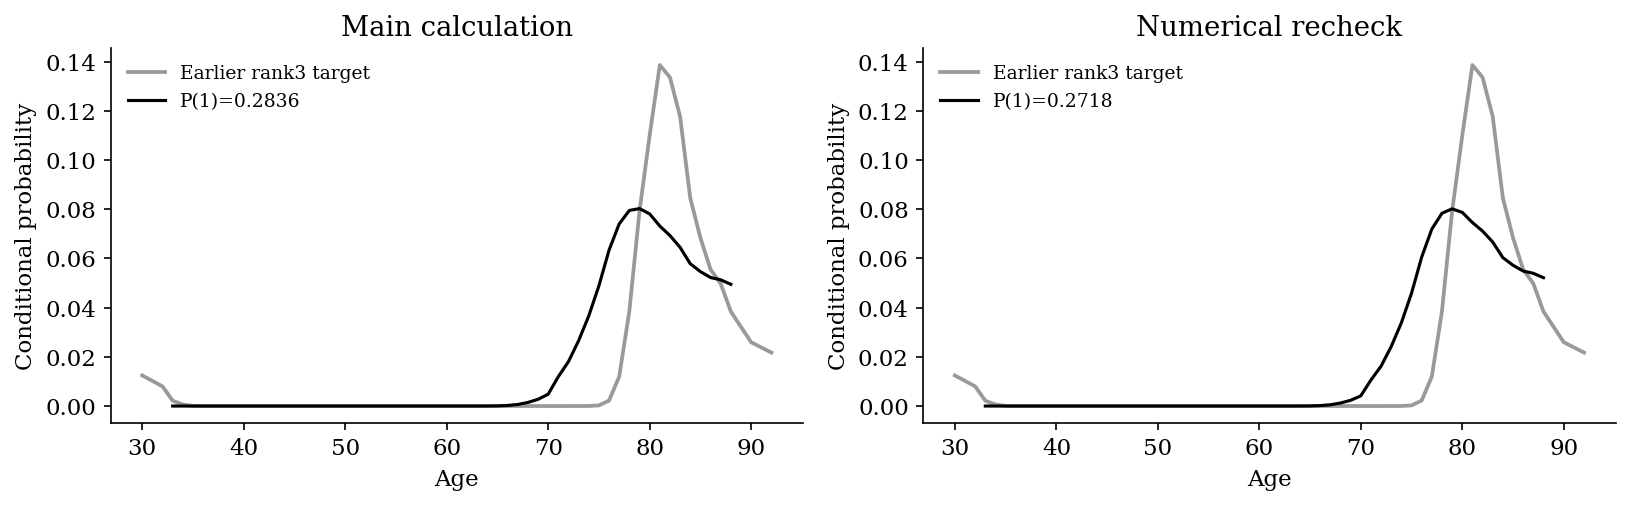

### #5: config134_n

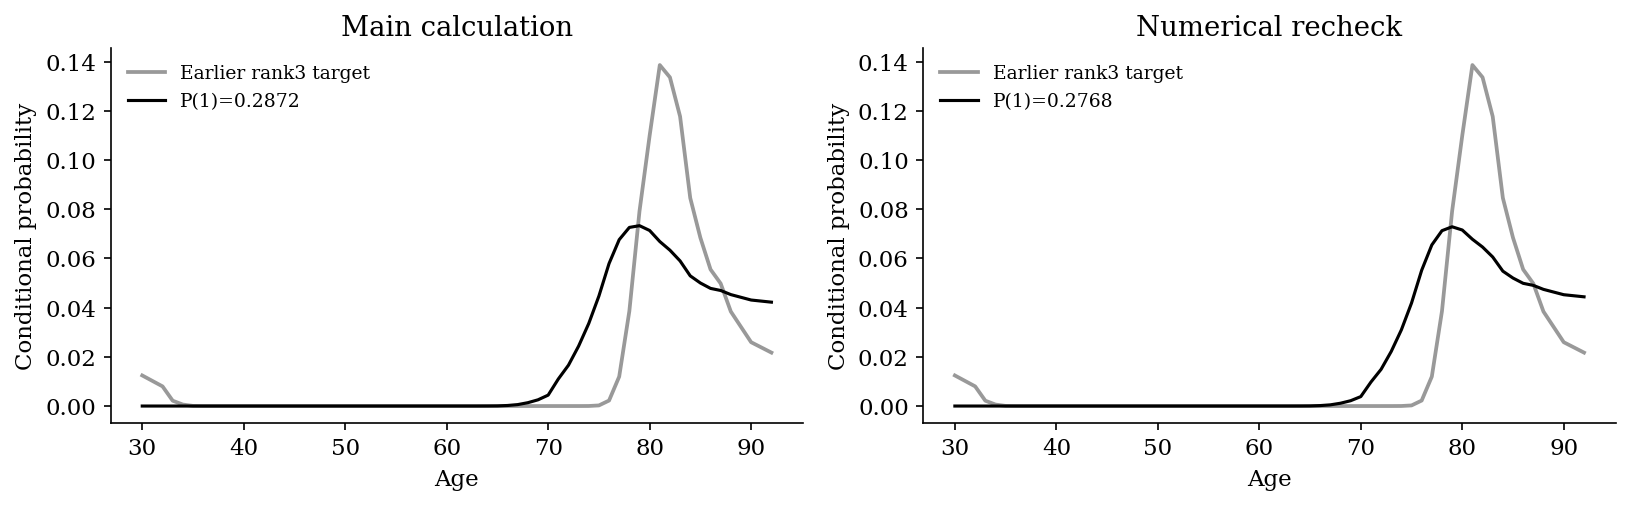

### #6: config022_n

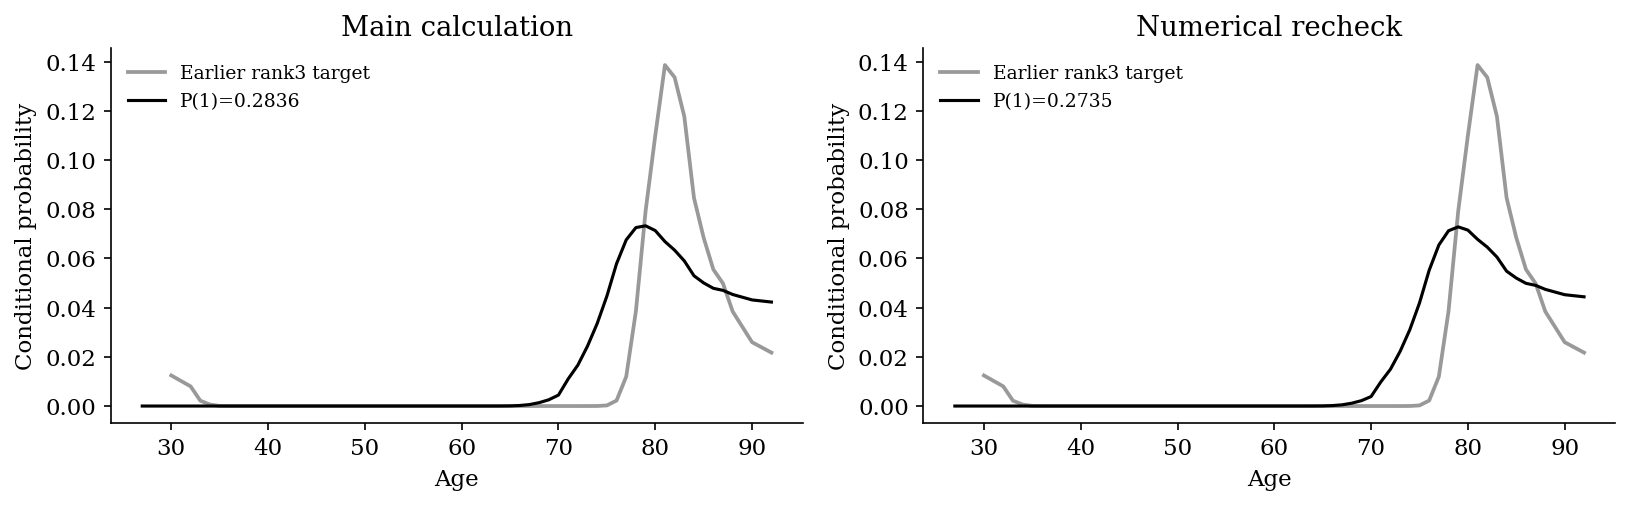

### #7: config305_n

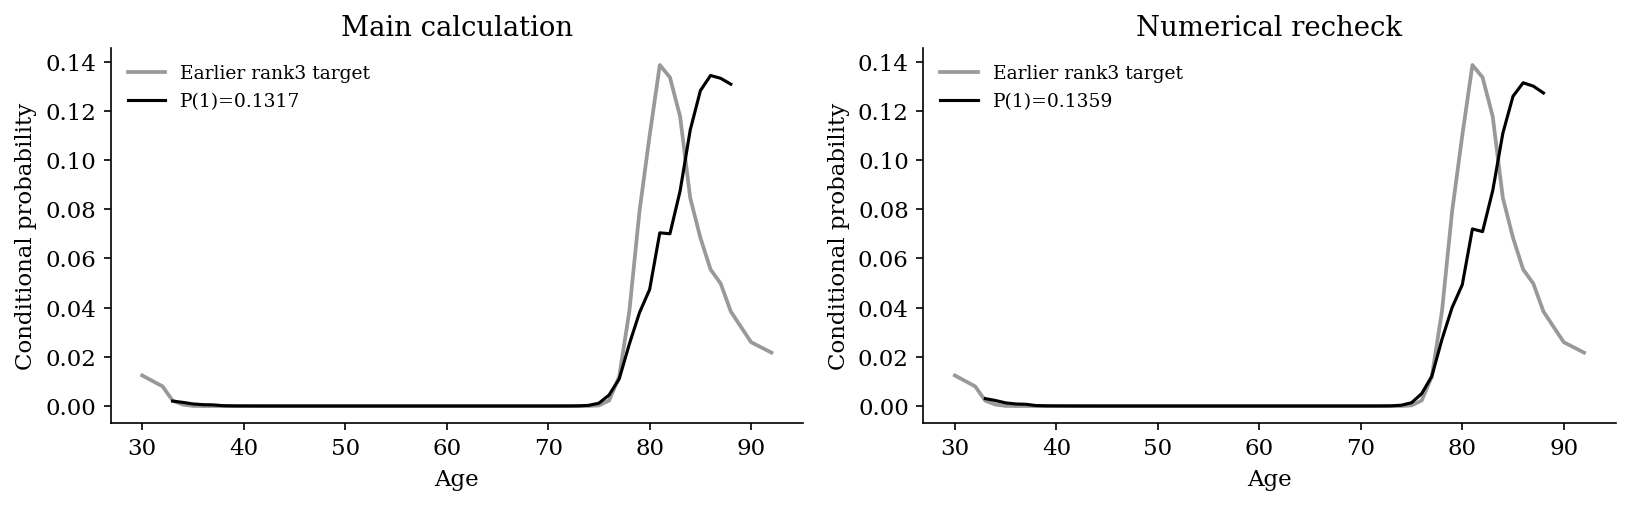

### #8: config193_n

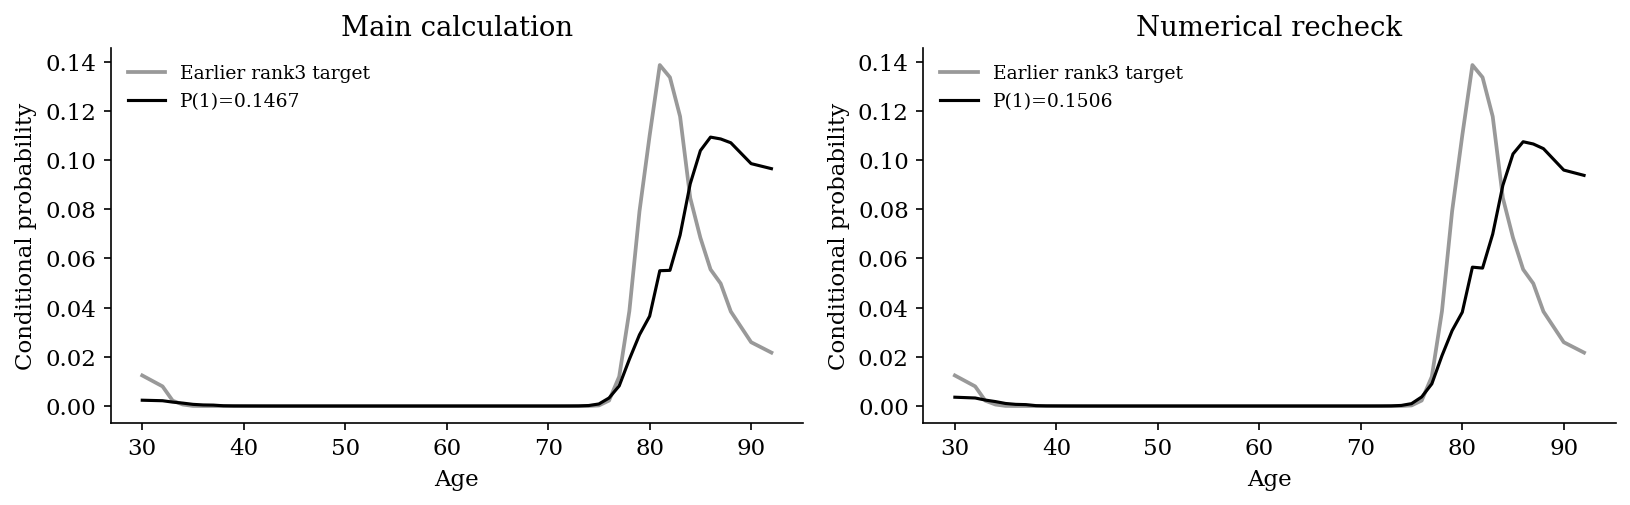

### #9: config081_n

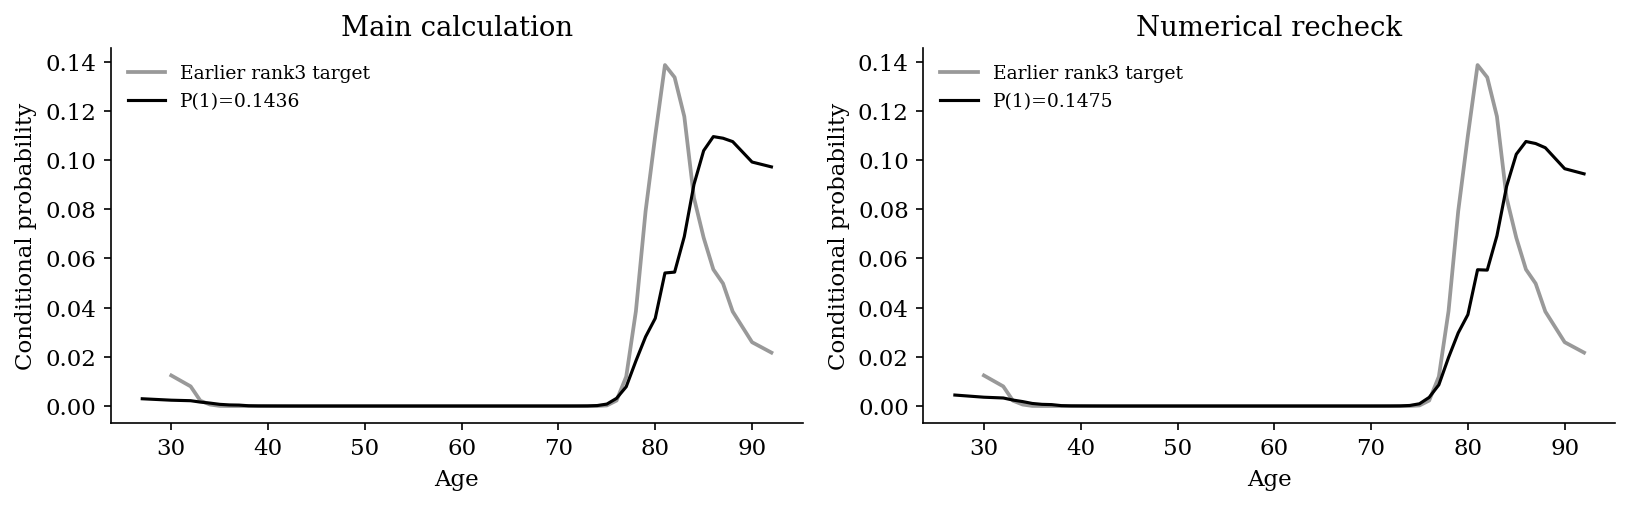

### #10: config022_p

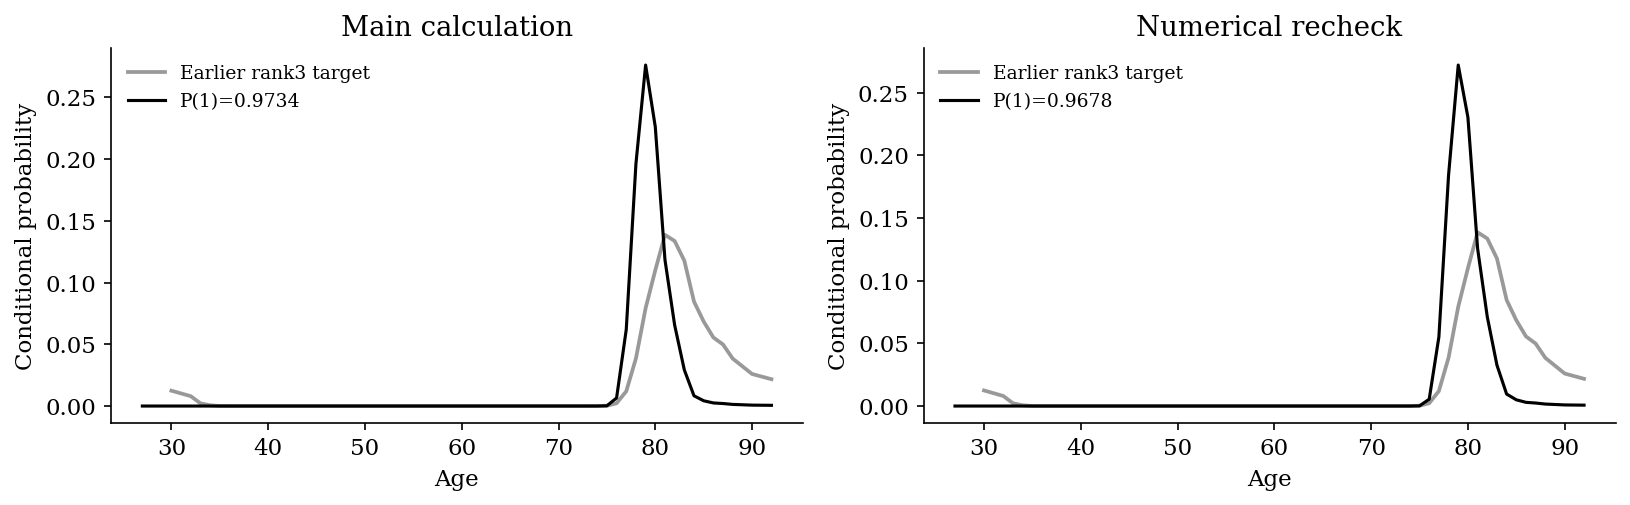

### #11: config134_p

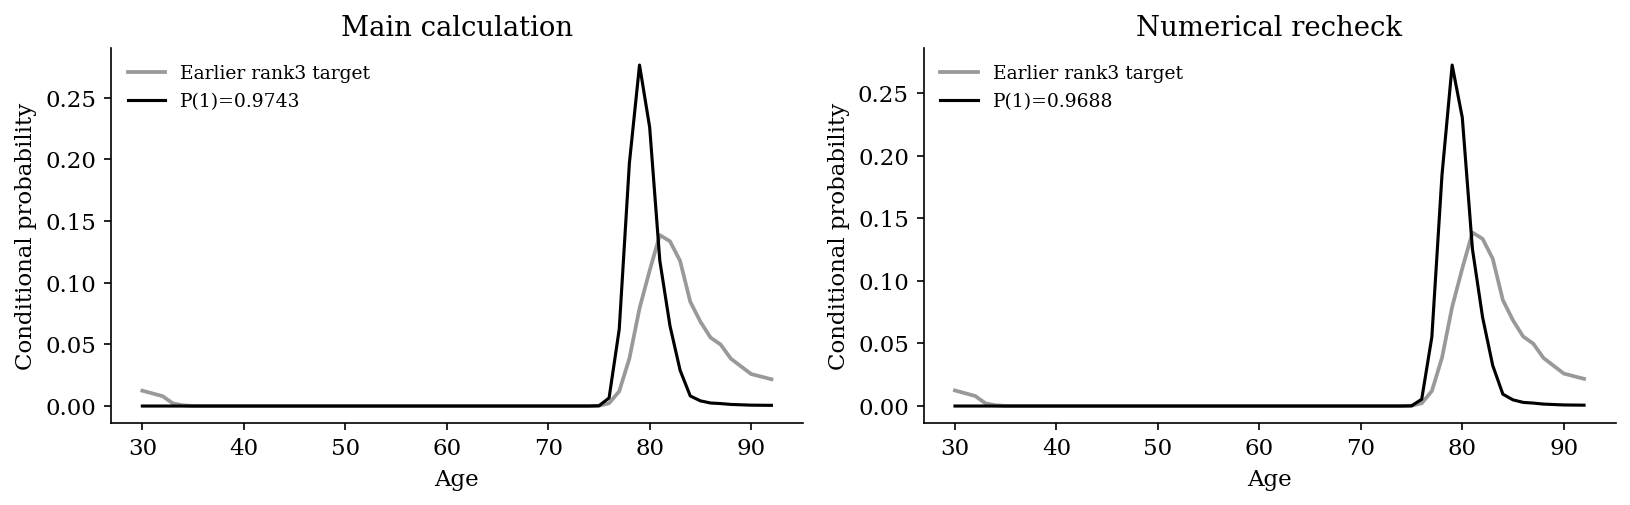

### #12: config246_p

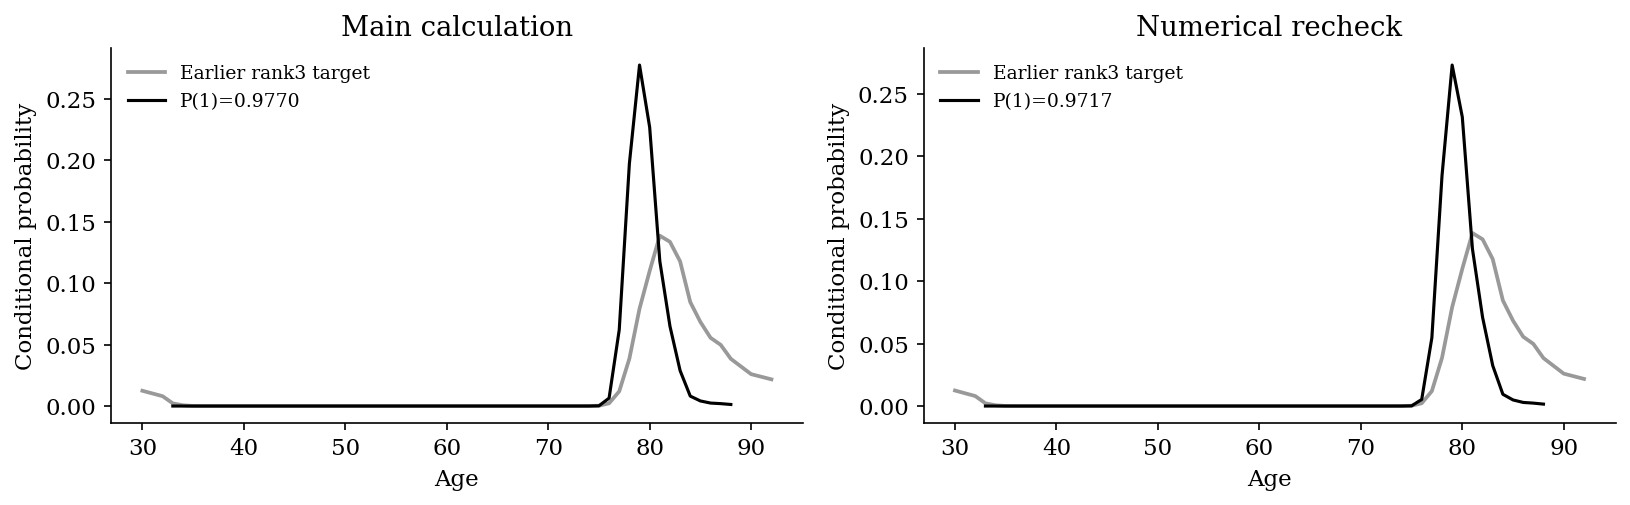

### #13: config027_n

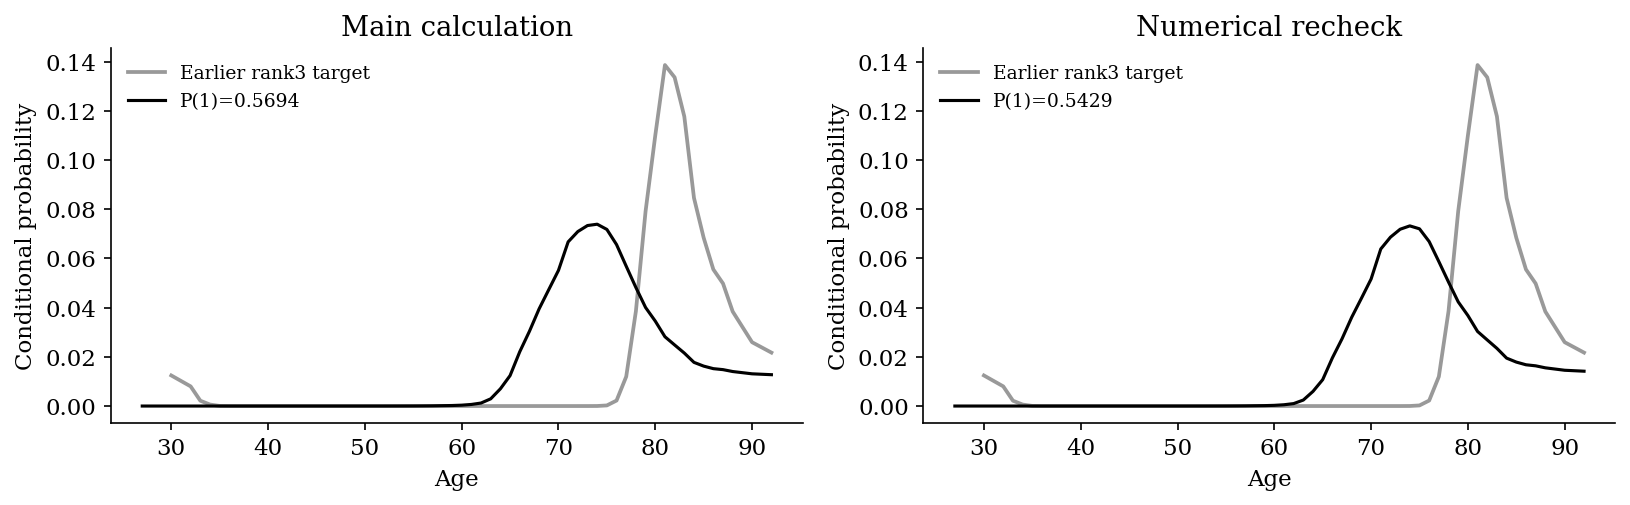

### #14: config139_n

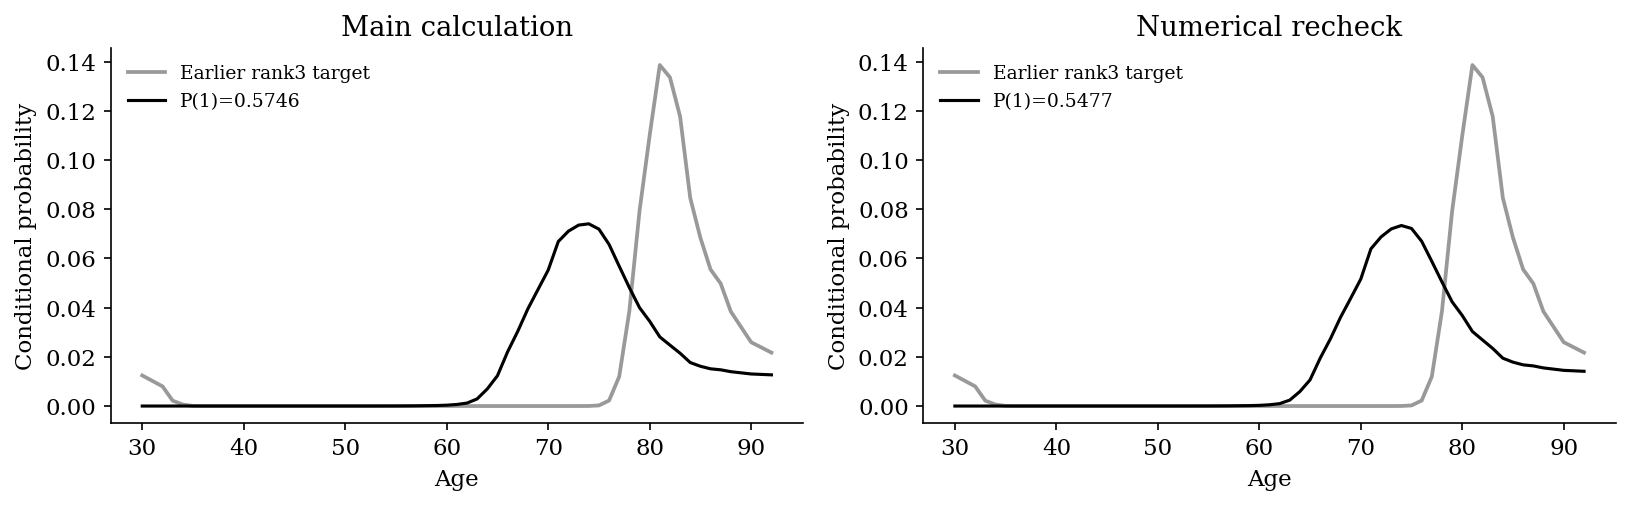

### #15: config188_n

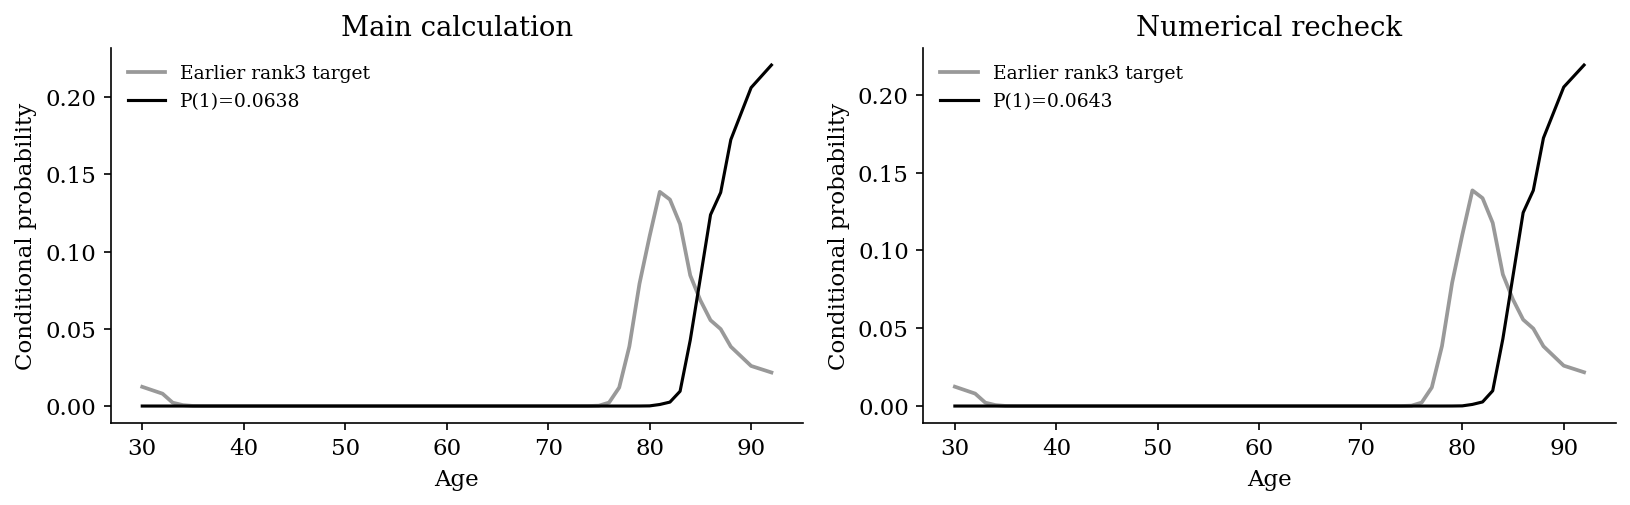

### #16: config076_n

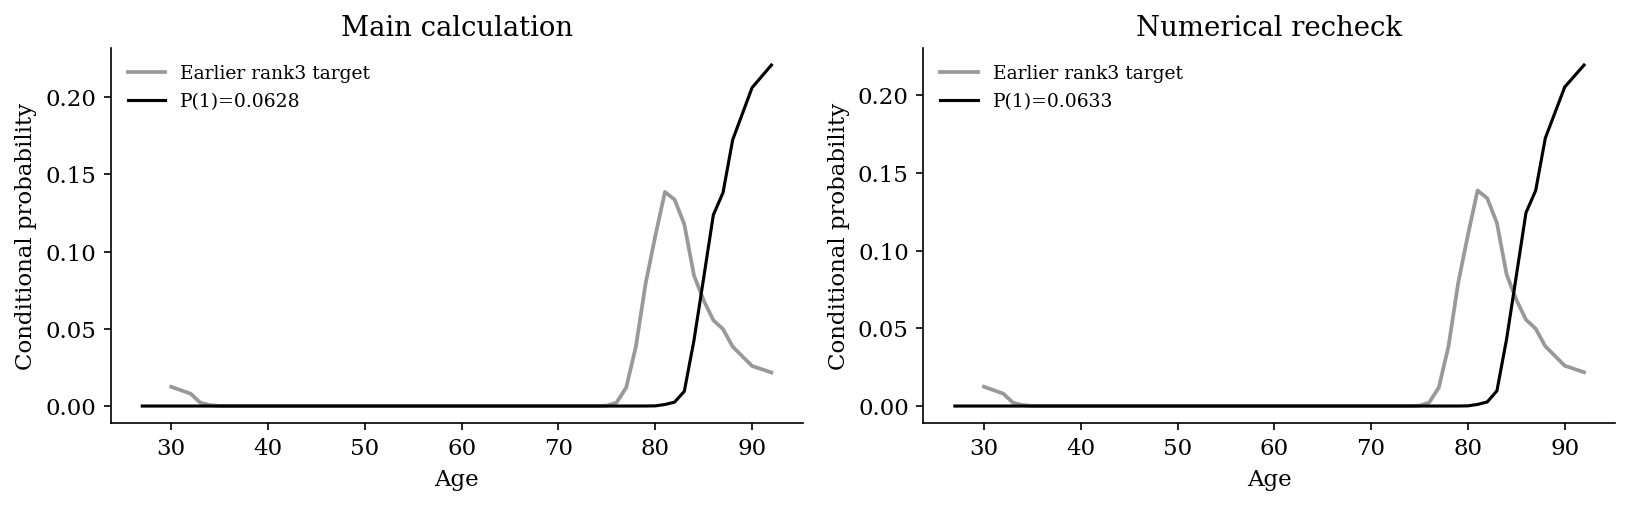

### #17: config300_n

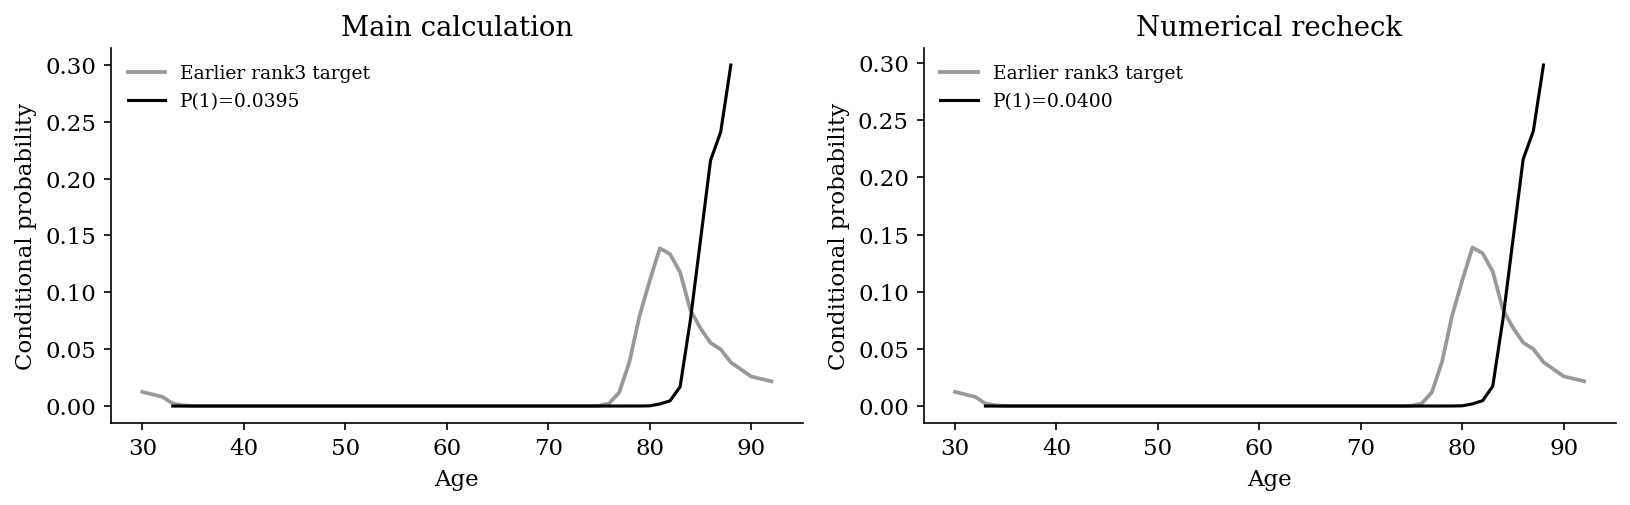

### #18: config251_n

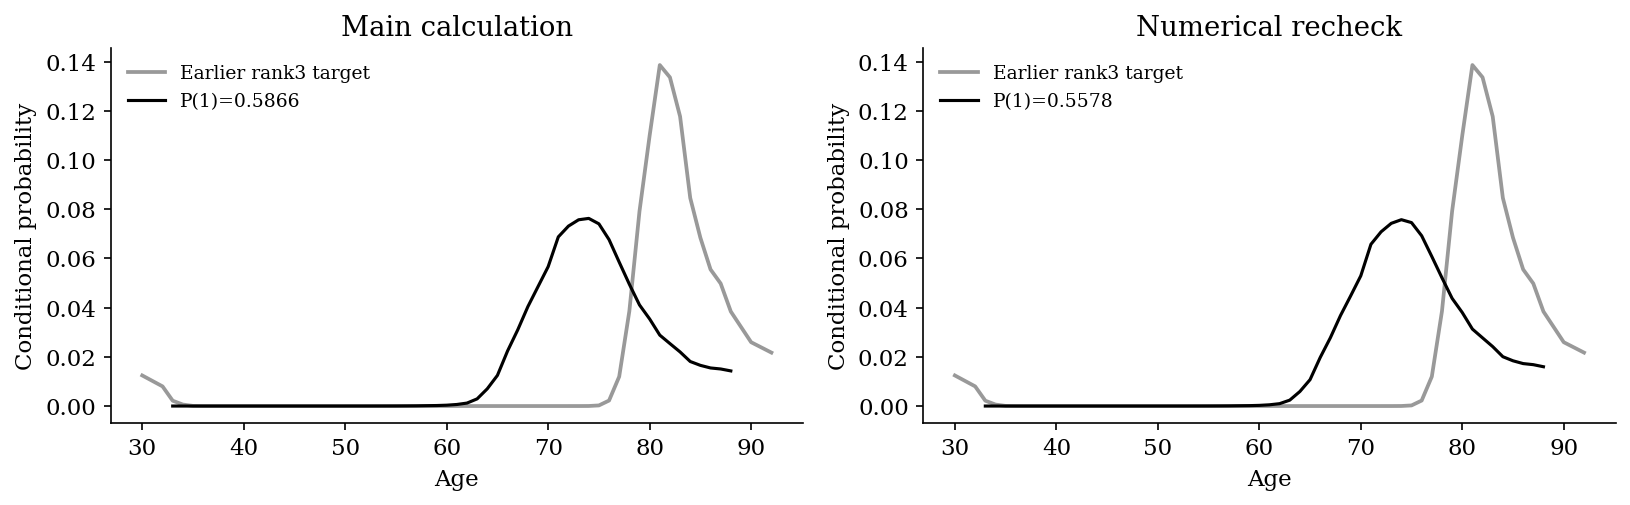

### #19: config223_n

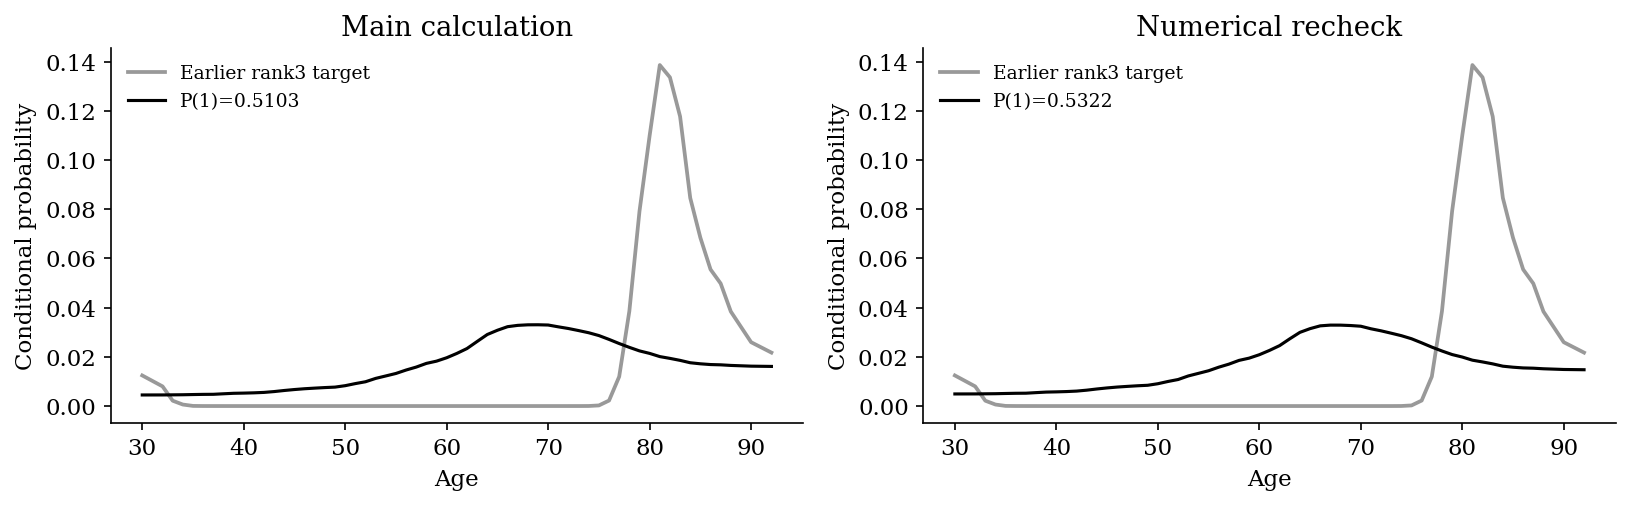

### #20: config111_n

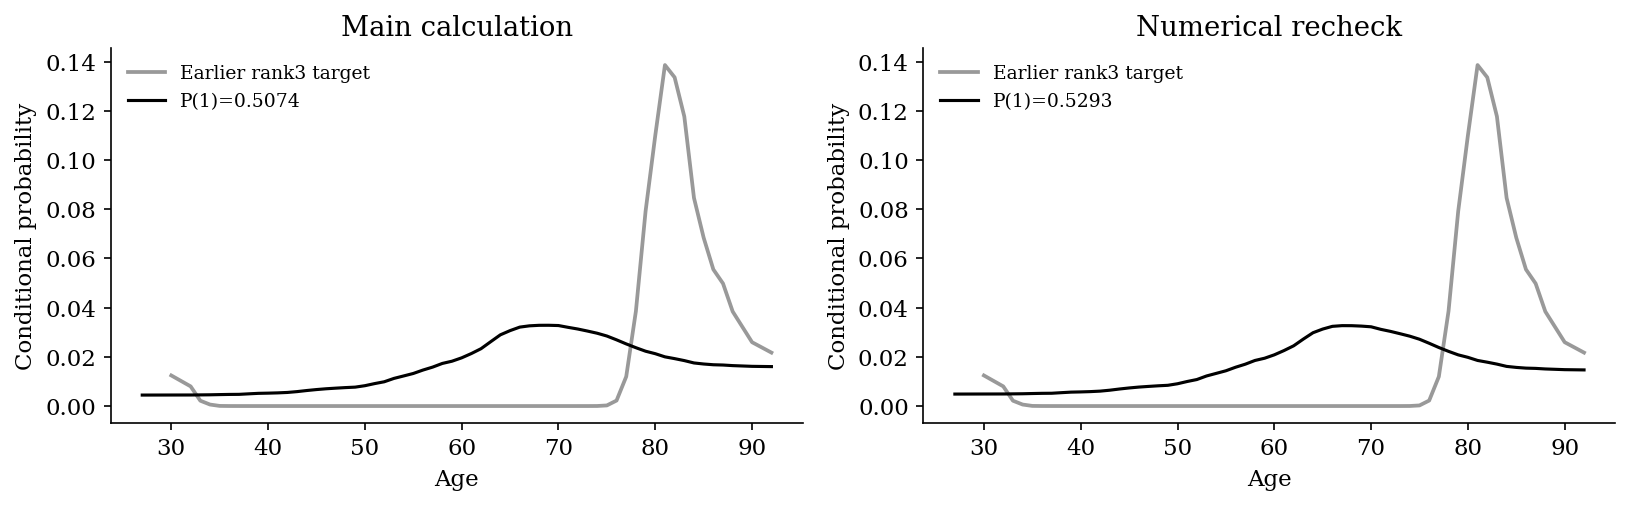

In [3]:
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
    'figure.dpi':150,'axes.spines.top':False,'axes.spines.right':False})
summary=pd.read_csv(root/'summary.csv');ranked=pd.read_csv(root/'ranked.csv')
print('All tested outcomes:');display(summary)
print('Top20:');display(ranked.head(20).style.hide(axis='index').format(precision=5))
print('Errors/non-evaluable settings:');display(json.loads((root/'errors.json').read_text()))
target=pickle.load((BASE/'scenario_100_100_q10_seed123.pkl').open('rb'))
def load_result(path,ident):
    saved=pickle.load(open(path,'rb'))
    return next(r for r in saved['results'] if r['id']==ident) if 'results' in saved else saved
for row in ranked.head(20).itertuples():
    a=load_result(row.checkpoint,row.id);b=load_result(row.check_checkpoint,row.id)
    display(Markdown(f'### #{row.rank}: {row.id}'))
    fig,axes=plt.subplots(1,2,figsize=(11,3.5))
    for ax,r,label in zip(axes,(a,b),('Main calculation','Numerical recheck')):
        ax.plot(target['ages'],target['conditional'],color='.6',lw=1.8,label='Earlier rank3 target')
        ax.plot(r['ages'],r['conditional'],color='black',lw=1.5,label=f"P(1)={r['P_1']:.4f}")
        ax.set(xlabel='Age',ylabel='Conditional probability',title=label)
        ax.legend(frameon=False,fontsize=9)
    fig.tight_layout();plt.show()


Paired comparison, same model configuration and normalization (screening results):


,id,denominator_whole,P_1_whole,P_1_segmented,correlation_whole,correlation_segmented,TV_to_rank3_whole,TV_to_rank3_segmented,TV_improvement_from_segmenting
0,config000_n,n,1.000000,1.000000,0.925832,-0.000184,0.976744,0.999980,-2.323653e-02
1,config000_p,p,1.000000,1.000000,0.925832,-0.000184,0.976744,1.000000,-2.325631e-02
2,config001_n,n,1.000000,1.000000,0.925832,-0.000184,0.976756,0.999998,-2.324204e-02
3,config001_p,p,1.000000,1.000000,0.925832,-0.000184,0.994071,1.000000,-5.928938e-03
4,config002_n,n,1.000000,1.000000,0.925832,-0.000184,0.979115,0.999998,-2.088311e-02
...,...,...,...,...,...,...,...,...,...
667,config333_p,p,1.000000,1.000000,0.962890,0.282617,1.000000,1.000000,-4.145027e-07
668,config334_n,n,0.905182,1.000000,0.954674,0.397644,0.956323,0.999973,-4.364975e-02
669,config334_p,p,0.999985,1.000000,0.954674,0.397644,0.996504,1.000000,-3.495363e-03
670,config335_n,n,0.453171,0.519200,0.945568,0.358144,0.745009,0.764511,-1.950181e-02


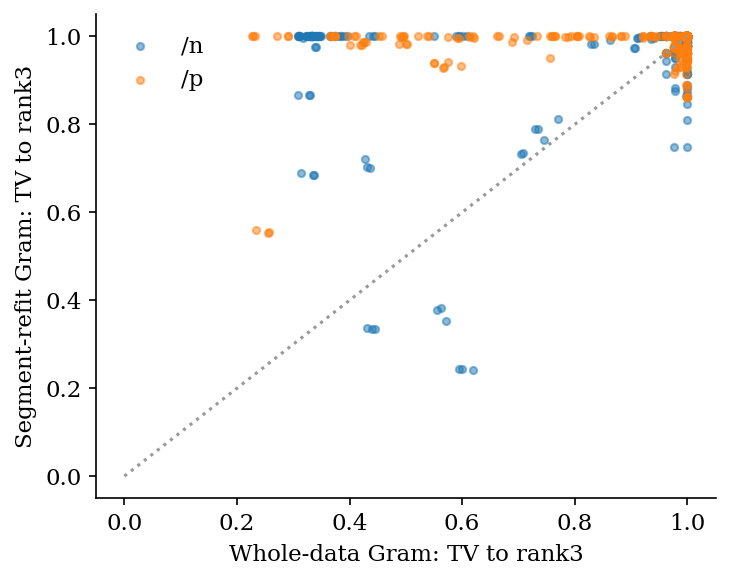

In [4]:
paired_path=root/'paired_whole_vs_segmented.csv'
if paired_path.exists():
    paired=pd.read_csv(paired_path)
    paired['TV_improvement_from_segmenting']=paired.TV_to_rank3_whole-paired.TV_to_rank3_segmented
    print('Paired comparison, same model configuration and normalization (screening results):')
    display(paired[['id','denominator_whole','P_1_whole','P_1_segmented','correlation_whole',
        'correlation_segmented','TV_to_rank3_whole','TV_to_rank3_segmented','TV_improvement_from_segmenting']])
    fig,ax=plt.subplots(figsize=(5,4))
    for divisor,g in paired.groupby('denominator_whole'):
        ax.scatter(g.TV_to_rank3_whole,g.TV_to_rank3_segmented,s=12,alpha=.5,label='/'+divisor)
    ax.plot([0,1],[0,1],color='.6',ls=':')
    ax.set(xlabel='Whole-data Gram: TV to rank3',ylabel='Segment-refit Gram: TV to rank3')
    ax.legend(frameon=False);fig.tight_layout();plt.show()


## Balanced-class segment refits
Only the segment fits use weights n_segment/(2 n_class), computed separately within each estimated segment. Pilot selection and posterior regression remain unchanged. A single-class segment is reported as non-evaluable. This is an exploratory estimator modification, not a calibration guarantee.

In [5]:
unbalanced_root=root
root=run('segmented_balanced')
print(root)

GRAM STUDY COMPLETE segmented_balanced results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced


results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced


All tested outcomes:


,presence,absence,Delta,intercept,aux_loss,penalty,strength,method,budget,id,...,correlation,rho_11,rho_12,rho_22,max_state_residual,power,seed,checkpoint,max_aux_kkt,max_post_kkt
0,1.000000,0.000000e+00,1,False,squared,none,0.00000,fista,8,config000_n,...,-0.000110,378.077077,-0.041832,385.400227,1.977860e-02,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,3.076424e-18,2.052392e-04
1,1.000000,0.000000e+00,1,False,squared,none,0.00000,fista,8,config000_p,...,-0.000110,5815.512859,-0.643457,5928.156223,9.097952e-02,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,3.076424e-18,2.052392e-04
2,1.000000,0.000000e+00,1,False,squared,none,0.00000,fista,16,config001_n,...,-0.000110,378.077077,-0.041832,385.400227,1.977860e-02,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,3.076424e-18,1.901676e-04
3,1.000000,0.000000e+00,1,False,squared,none,0.00000,fista,16,config001_p,...,-0.000110,5815.512859,-0.643457,5928.156223,9.097952e-02,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,3.076424e-18,1.901676e-04
4,1.000000,0.000000e+00,1,False,squared,none,0.00000,fista,20,config002_n,...,-0.000110,378.077077,-0.041832,385.400227,1.977860e-02,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,3.076424e-18,1.803467e-04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
667,1.000000,0.000000e+00,5,True,logistic,l2,0.00001,full,0,config333_p,...,0.287199,25.979904,5.856834,16.007492,3.981927e-10,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,2.982834e-09,2.982834e-09
668,1.000000,2.789714e-67,5,True,logistic,l2,0.00010,full,0,config334_n,...,0.412392,0.241894,0.075743,0.139457,6.786950e-10,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,3.865134e-11,3.865134e-11
669,1.000000,9.711900e-237,5,True,logistic,l2,0.00010,full,0,config334_p,...,0.412392,3.720771,1.165068,2.145108,4.036225e-10,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,3.865134e-11,3.865134e-11
670,0.998306,1.694011e-03,5,True,logistic,l2,0.00100,full,0,config335_n,...,0.371399,0.006820,0.001983,0.004180,7.468753e-10,9,123,results/myocardial_gram_pair_1ce06b10b4f5/segm...,1.229152e-09,1.229152e-09


Top20:


rank,presence,absence,Delta,intercept,aux_loss,penalty,strength,method,budget,id,mode,denominator,pilot,pilot_age,P_1,TV_to_rank3,peak_age,mass_above55,correlation,rho_11,rho_12,rho_22,max_state_residual,power,seed,checkpoint,max_aux_kkt,max_post_kkt,mean_TV_to_rank3,P1_min,P1_max,numerical_TV,check_checkpoint
1,0.20148,0.79852,5,True,squared,l2,0.00001,full,0,config305_n,segmented_balanced,n,1127,67.00000,0.20148,0.26233,85.00000,1.00000,0.25473,0.08585,0.01893,0.06434,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config305_n_p10s123.pkl,0.00000,0.00000,0.25673,0.20148,0.21136,0.02062,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config305_n_p10s42.pkl
2,0.20446,0.79554,2,True,squared,l2,0.00001,full,0,config193_n,segmented_balanced,n,1127,67.00000,0.20446,0.28111,86.00000,0.99999,0.25473,0.08585,0.01893,0.06434,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config193_n_p10s123.pkl,0.00000,0.00000,0.27398,0.20446,0.21258,0.01926,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config193_n_p10s42.pkl
3,0.19769,0.80231,1,True,squared,l2,0.00001,full,0,config081_n,segmented_balanced,n,1127,67.00000,0.19769,0.28935,86.00000,0.99999,0.25473,0.08585,0.01893,0.06434,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config081_n_p10s123.pkl,0.00000,0.00000,0.28151,0.19769,0.20529,0.01860,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config081_n_p10s42.pkl
4,0.57959,0.42041,1,True,squared,l1,0.00010,full,0,config077_n,segmented_balanced,n,1127,67.00000,0.57959,0.41813,78.00000,1.00000,0.27861,0.07789,0.01817,0.05461,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config077_n_p10s123.pkl,0.00000,0.00000,0.43086,0.57959,0.60605,0.02544,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config077_n_p10s42.pkl
5,0.59052,0.40948,2,True,squared,l1,0.00010,full,0,config189_n,segmented_balanced,n,1127,67.00000,0.59052,0.42428,78.00000,1.00000,0.27861,0.07789,0.01817,0.05461,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config189_n_p10s123.pkl,0.00000,0.00000,0.43715,0.59052,0.61740,0.02575,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config189_n_p10s42.pkl
6,0.61248,0.38752,5,True,squared,l1,0.00010,full,0,config301_n,segmented_balanced,n,1127,67.00000,0.61248,0.45106,78.00000,1.00000,0.27861,0.07789,0.01817,0.05461,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config301_n_p10s123.pkl,0.00000,0.00000,0.46369,0.61248,0.64070,0.02584,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config301_n_p10s42.pkl
7,1.00000,0.00000,1,False,logistic,none,0.00000,fista,30,config031_p,segmented_balanced,p,1177,68.00000,1.00000,0.88987,80.00000,1.00000,0.10486,93.87832,6.71856,43.72492,0.00053,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config031_p_p10s123.pkl,0.00015,0.00015,0.82063,1.00000,1.00000,0.69929,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config031_p_p10s42.pkl
8,1.00000,0.00000,2,False,logistic,l2,0.00000,full,0,config164_n,segmented_balanced,n,924,64.00000,1.00000,0.85082,81.00000,1.00000,0.30585,5.67807,0.99576,1.86681,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config164_n_p10s123.pkl,0.00000,0.00000,0.87041,1.00000,1.00000,0.98944,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config164_n_p10s42.pkl
9,1.00000,0.00000,1,False,logistic,l2,0.00000,full,0,config052_n,segmented_balanced,n,924,64.00000,1.00000,0.86126,81.00000,1.00000,0.30585,5.67807,0.99576,1.86681,0.00000,10,123,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config052_n_p10s123.pkl,0.00000,0.00000,0.87495,1.00000,1.00000,0.99852,results/myocardial_gram_pair_1ce06b10b4f5/segmented_balanced/config052_n_p10s42.pkl
10,1.00000,0.00000,5,False,logistic,l2,0.00000,full,0,config276_n,segmented_balanced,n,924,64.00000,1.00000,0.86139,80.0000

Errors/non-evaluable settings:


[]

### #1: config305_n

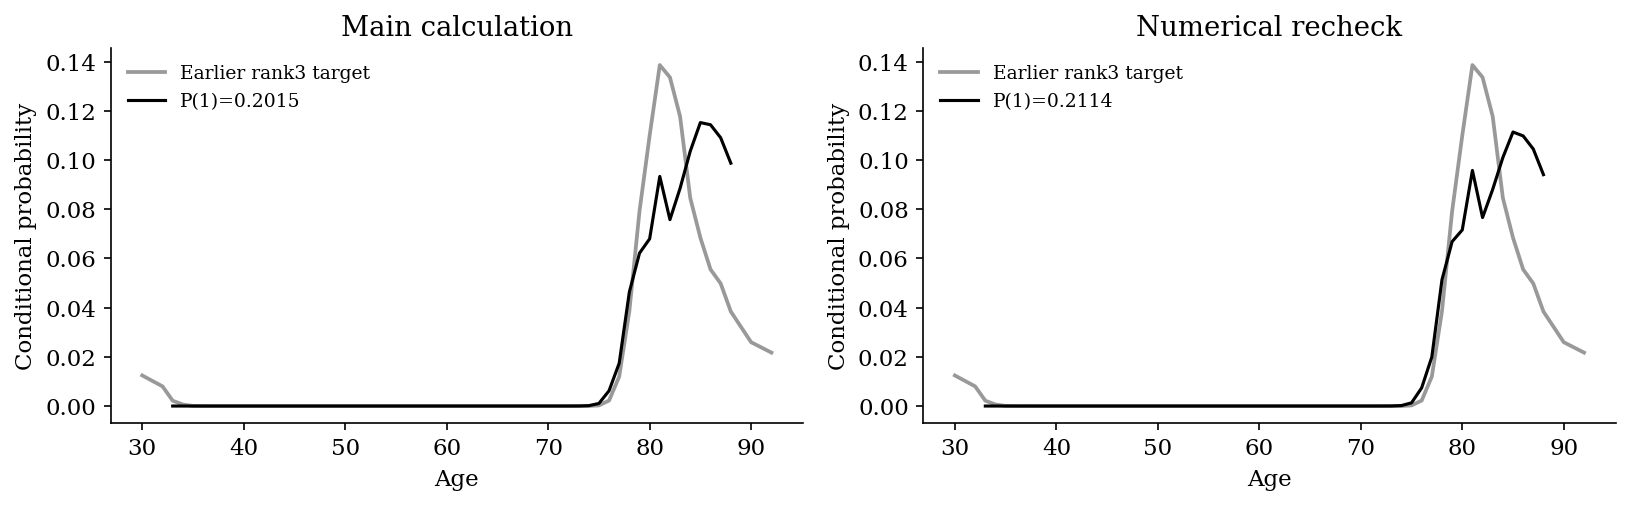

### #2: config193_n

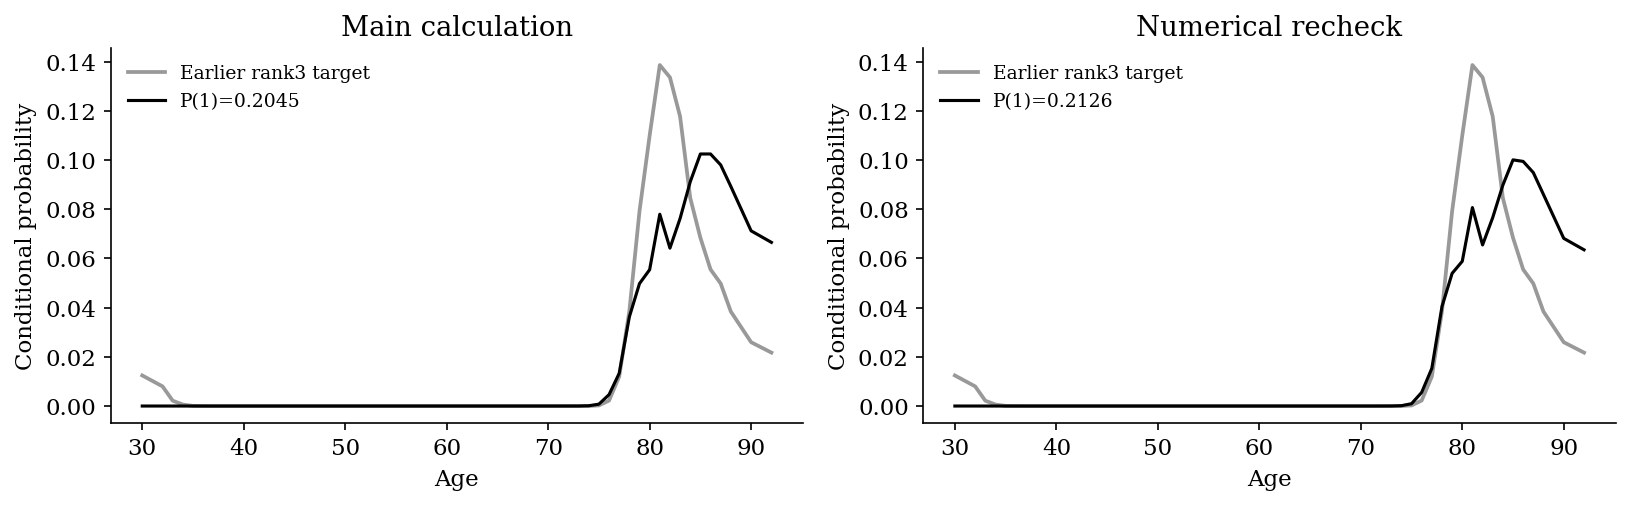

### #3: config081_n

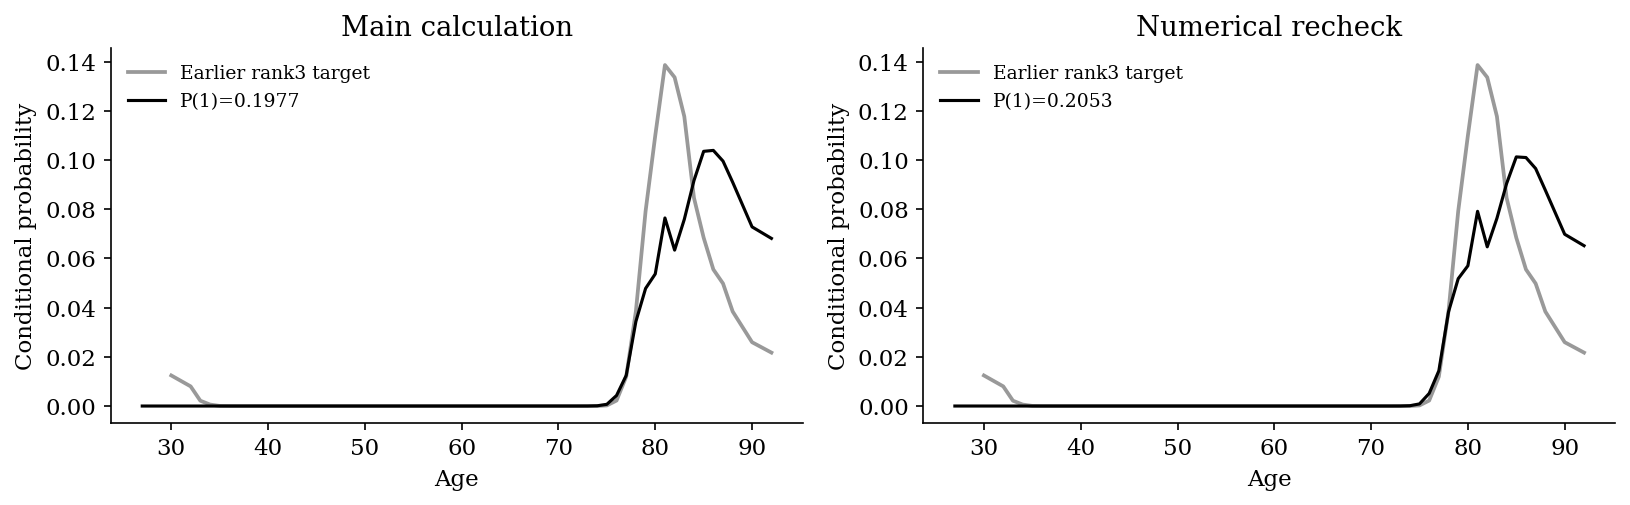

### #4: config077_n

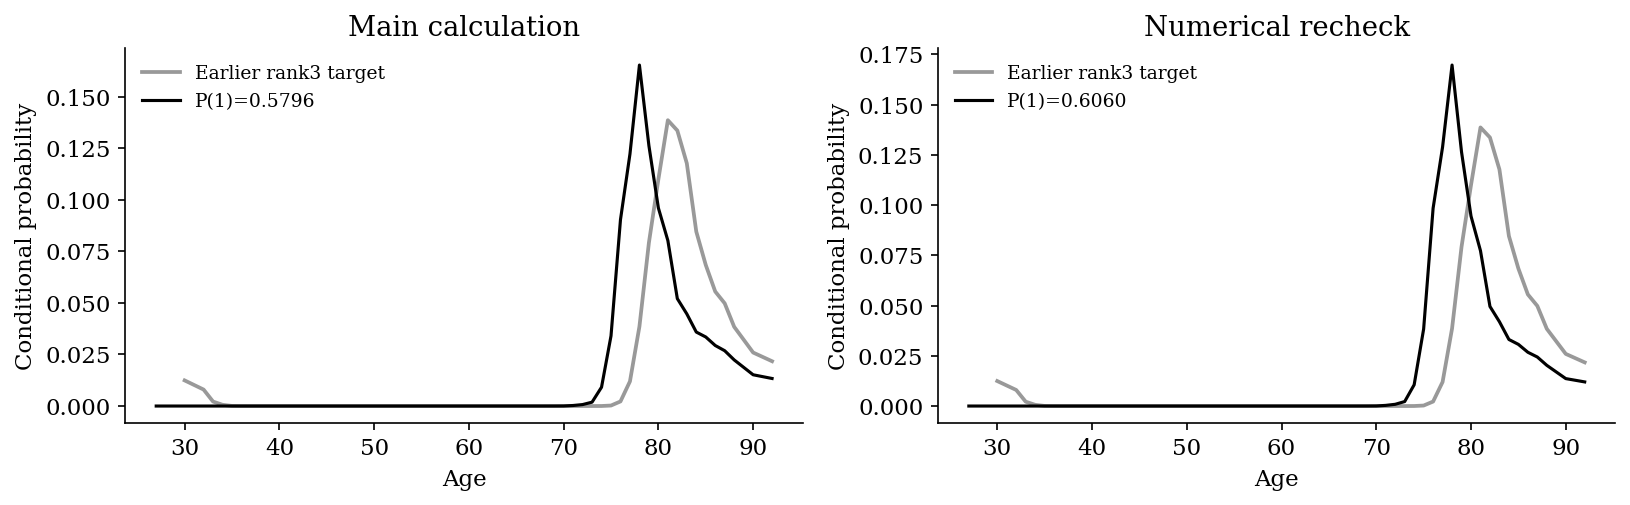

### #5: config189_n

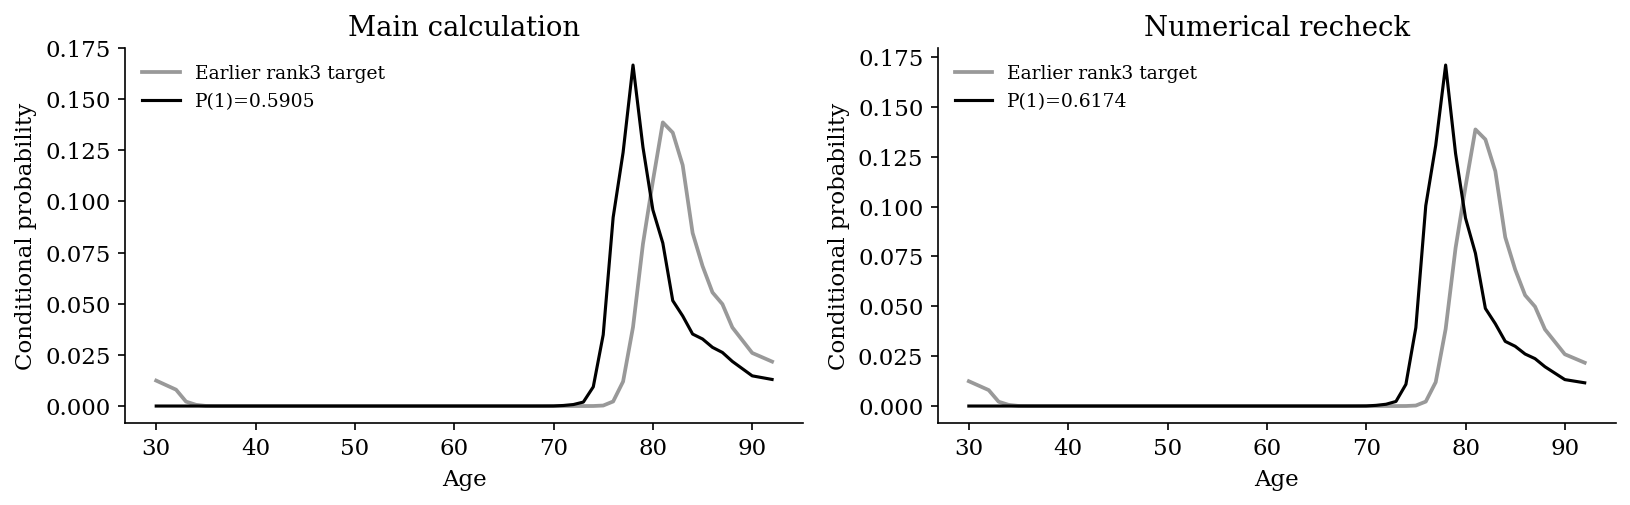

### #6: config301_n

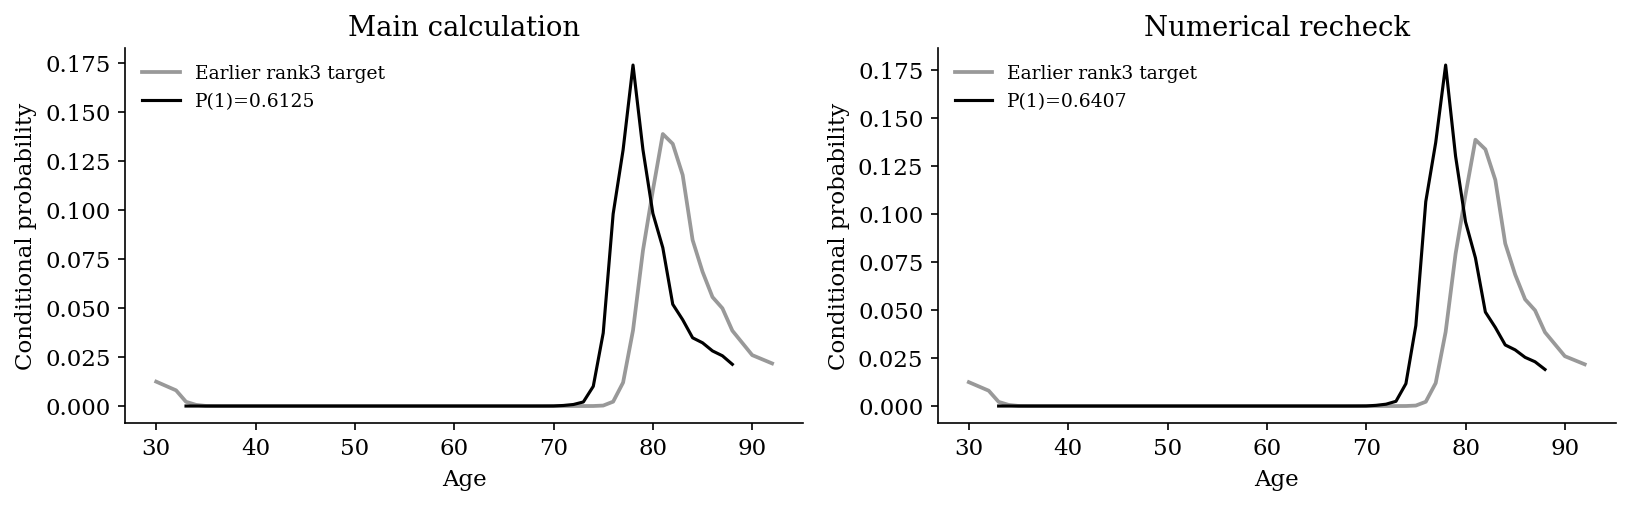

### #7: config031_p

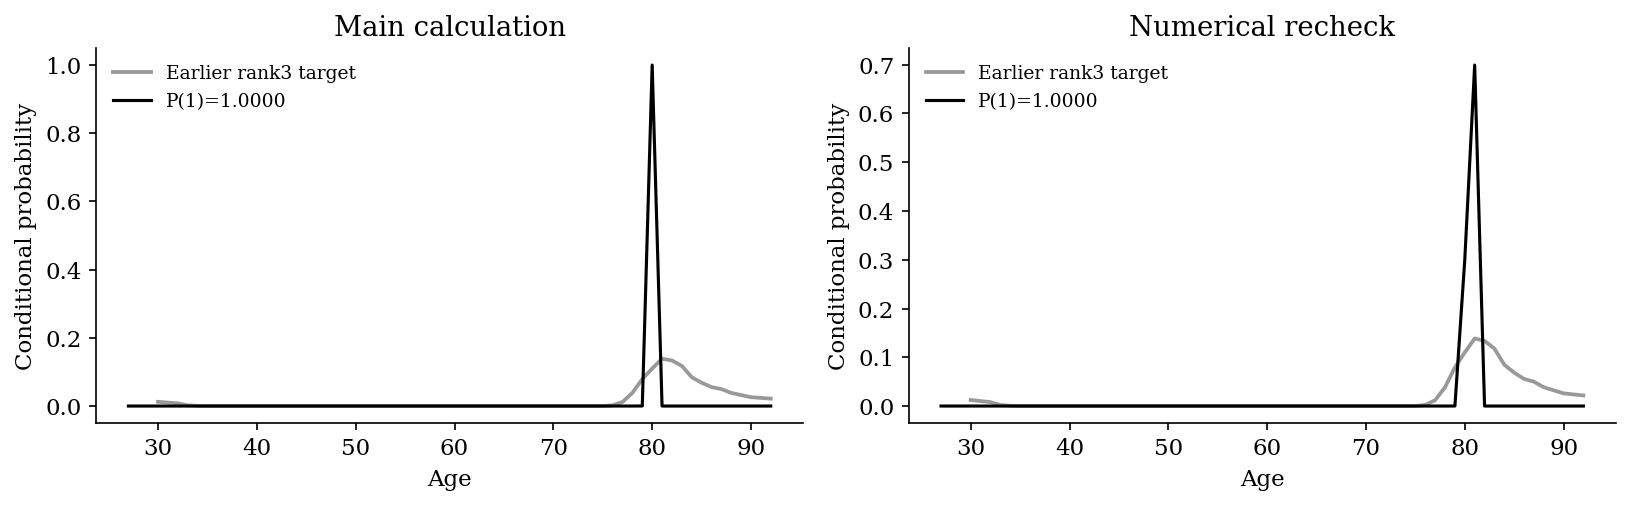

### #8: config164_n

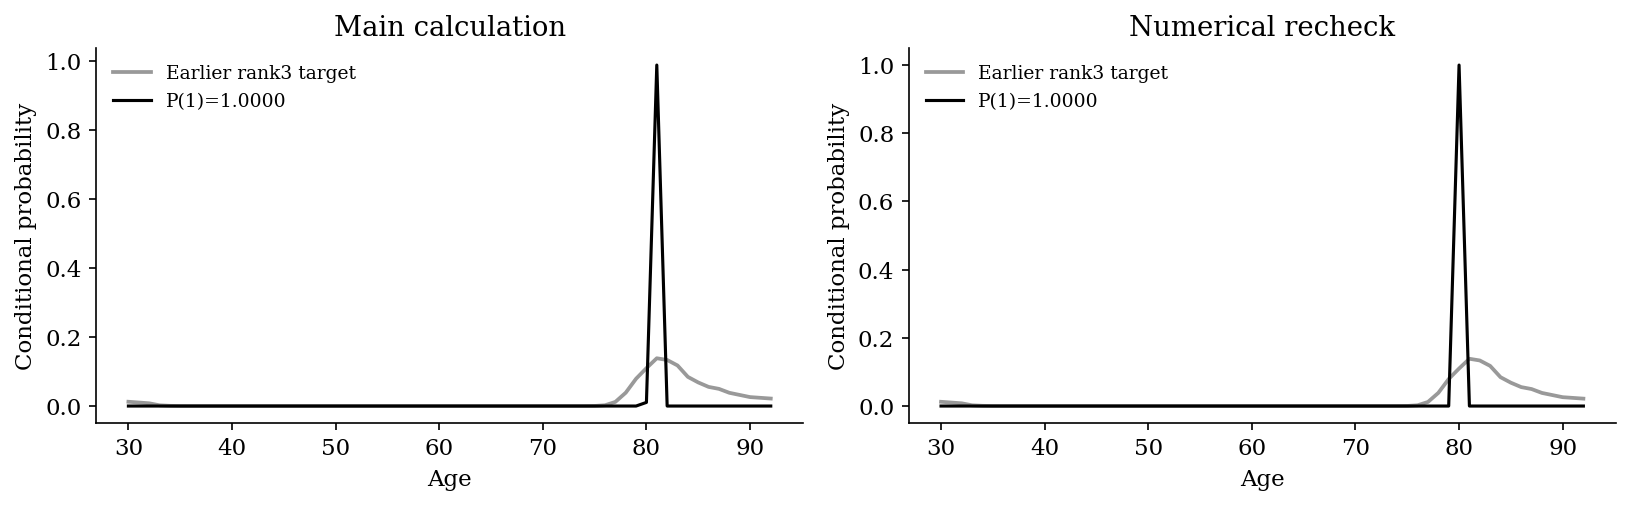

### #9: config052_n

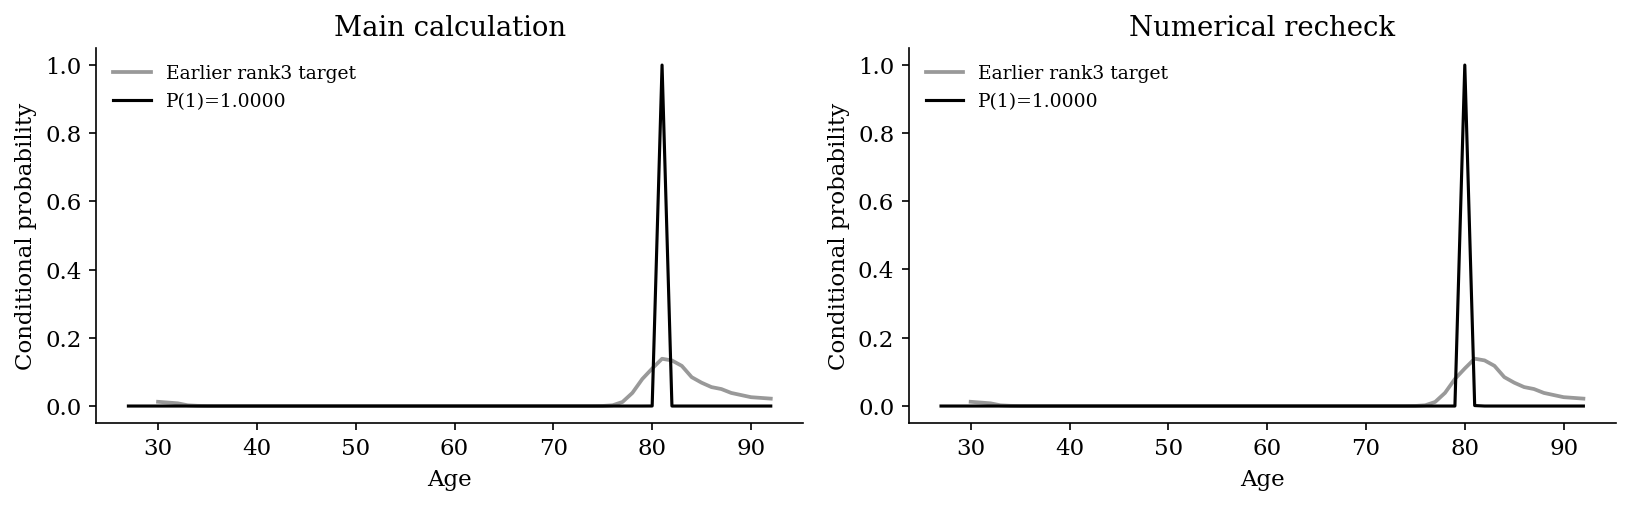

### #10: config276_n

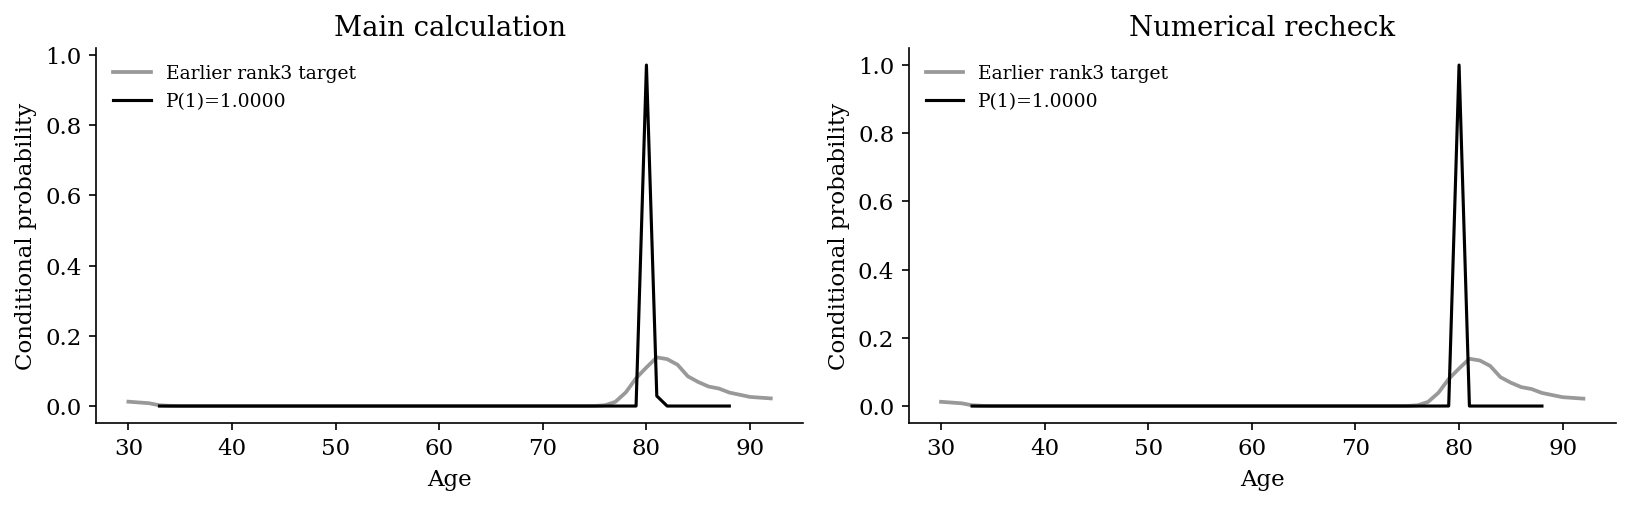

### #11: config143_p

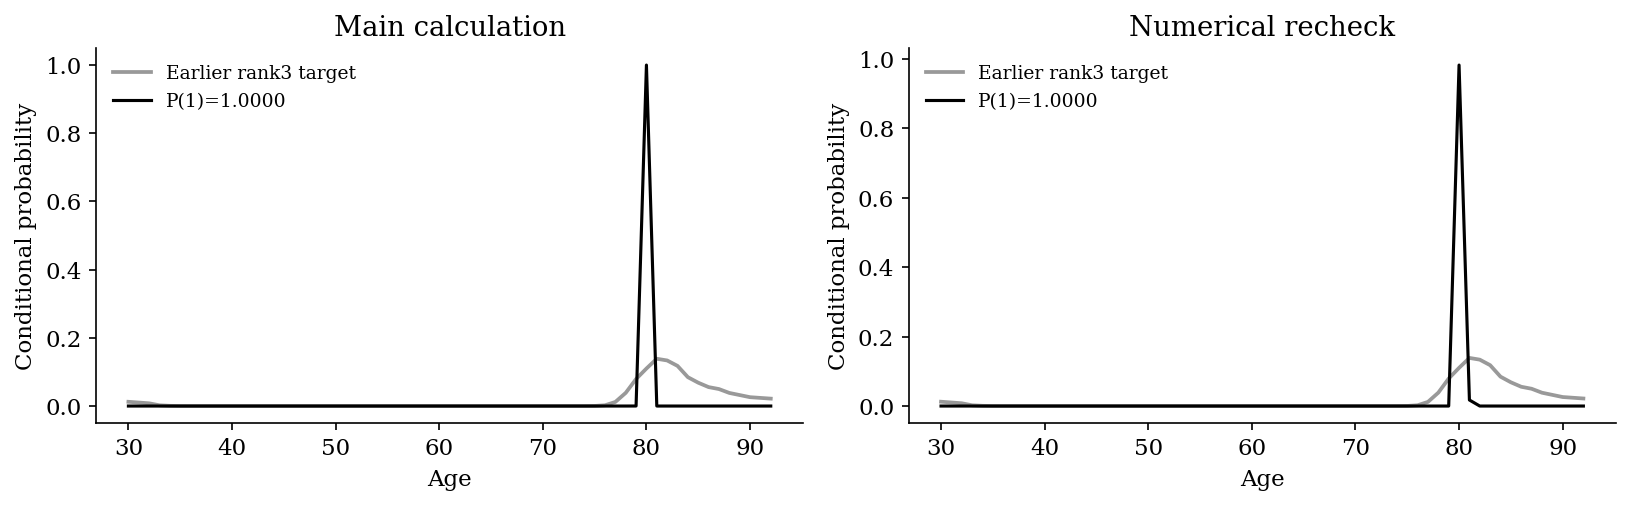

### #12: config255_p

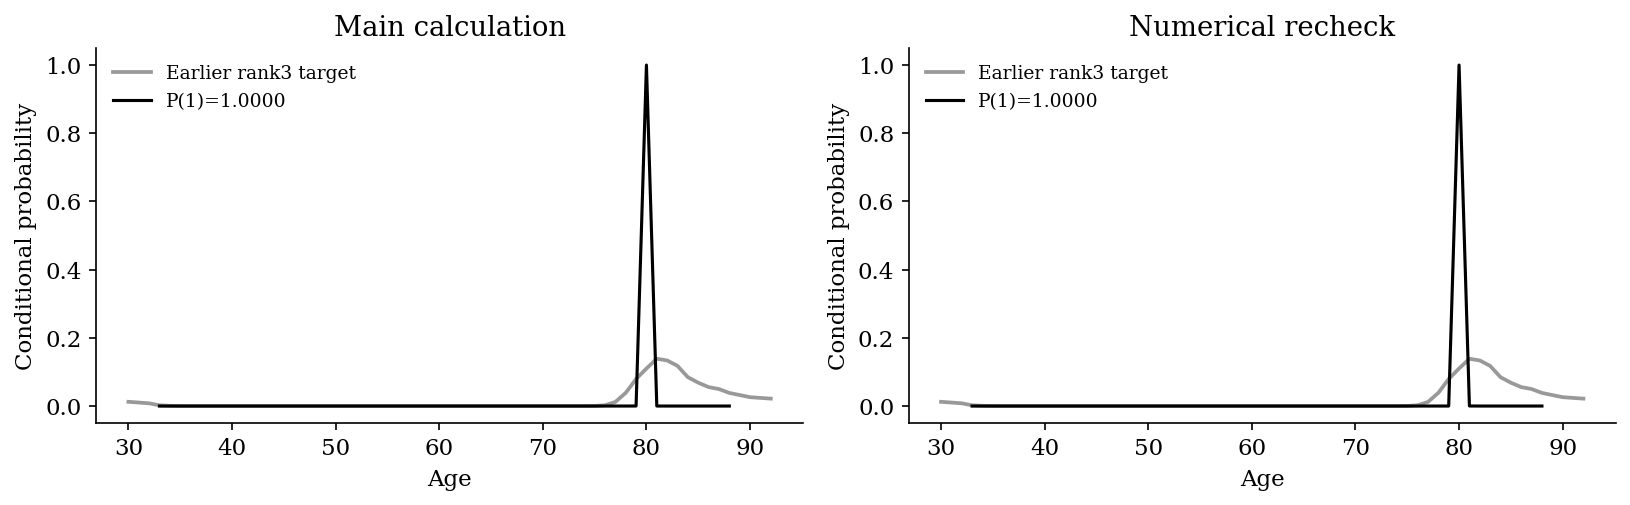

### #13: config024_p

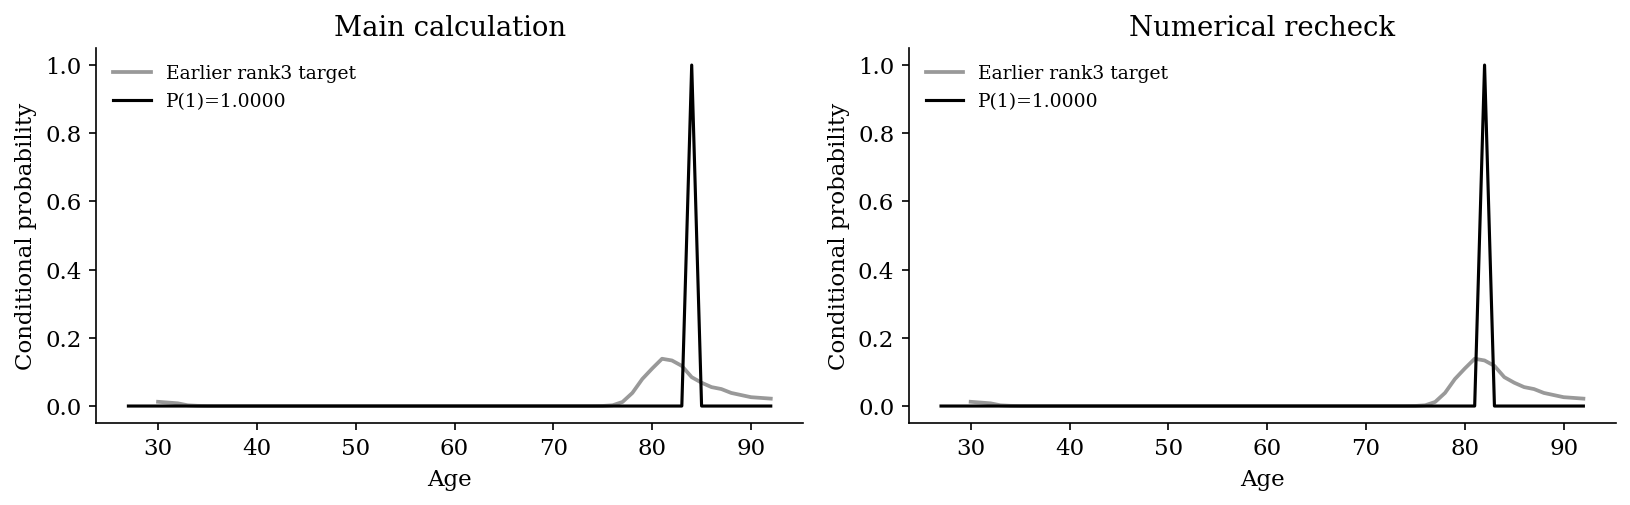

### #14: config024_n

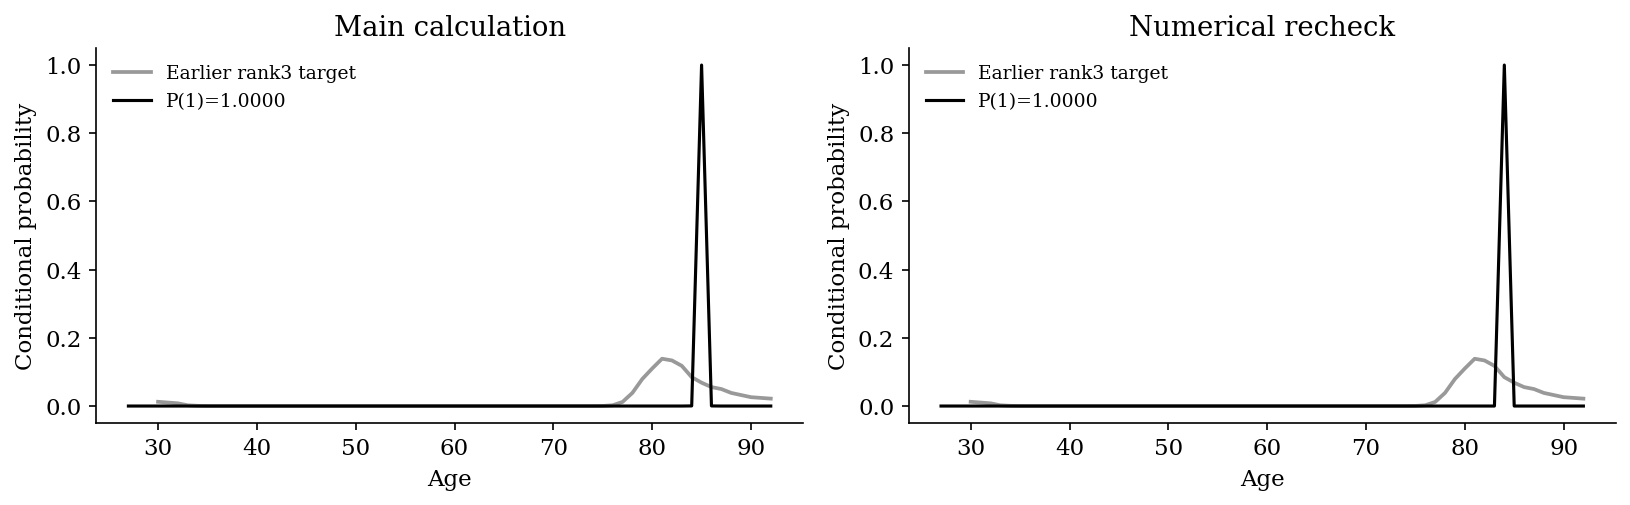

### #15: config005_n

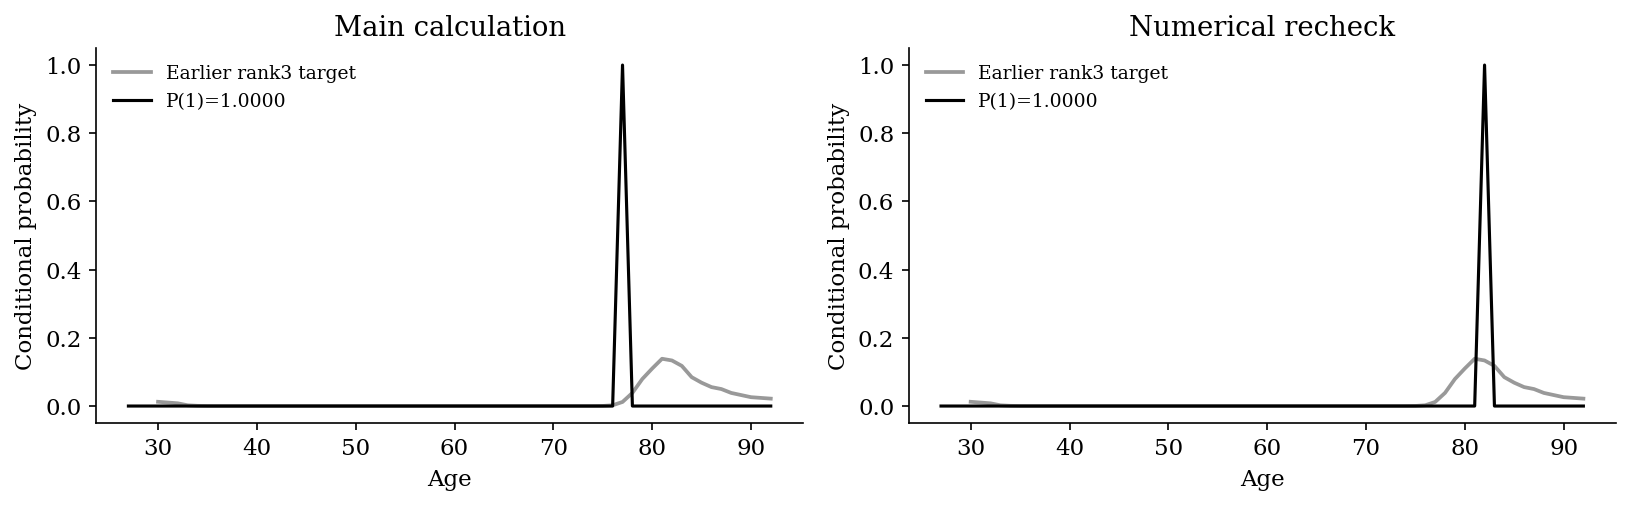

### #16: config121_n

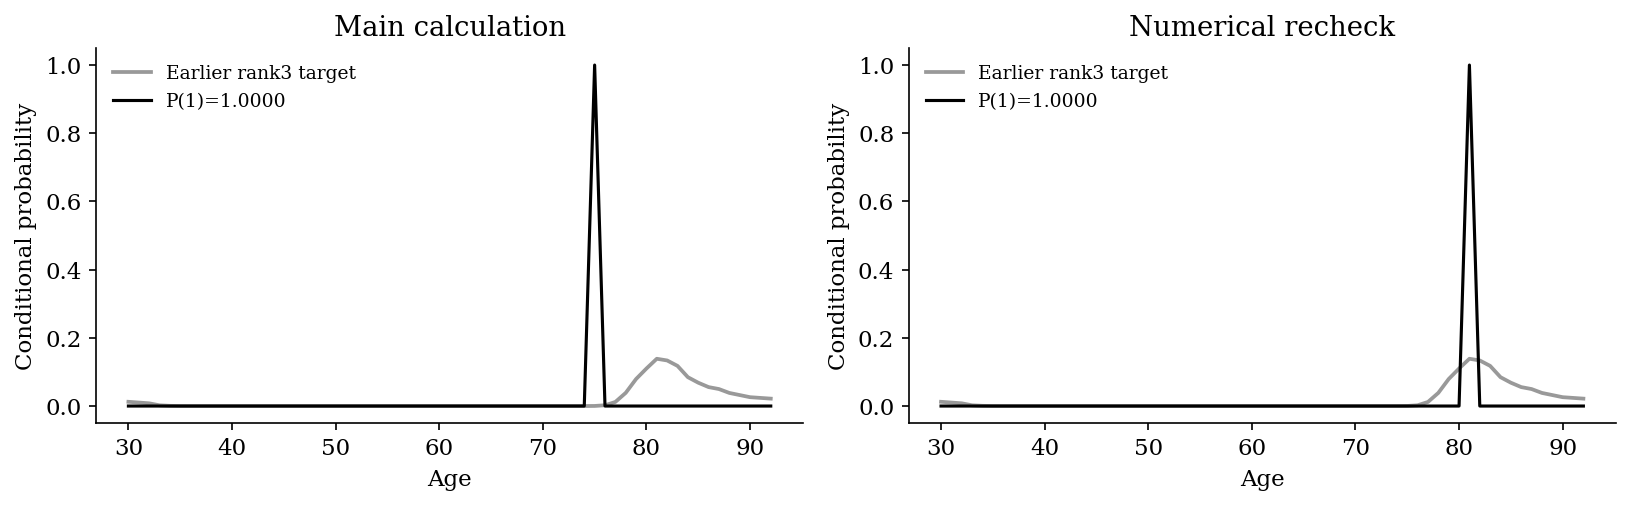

### #17: config186_p

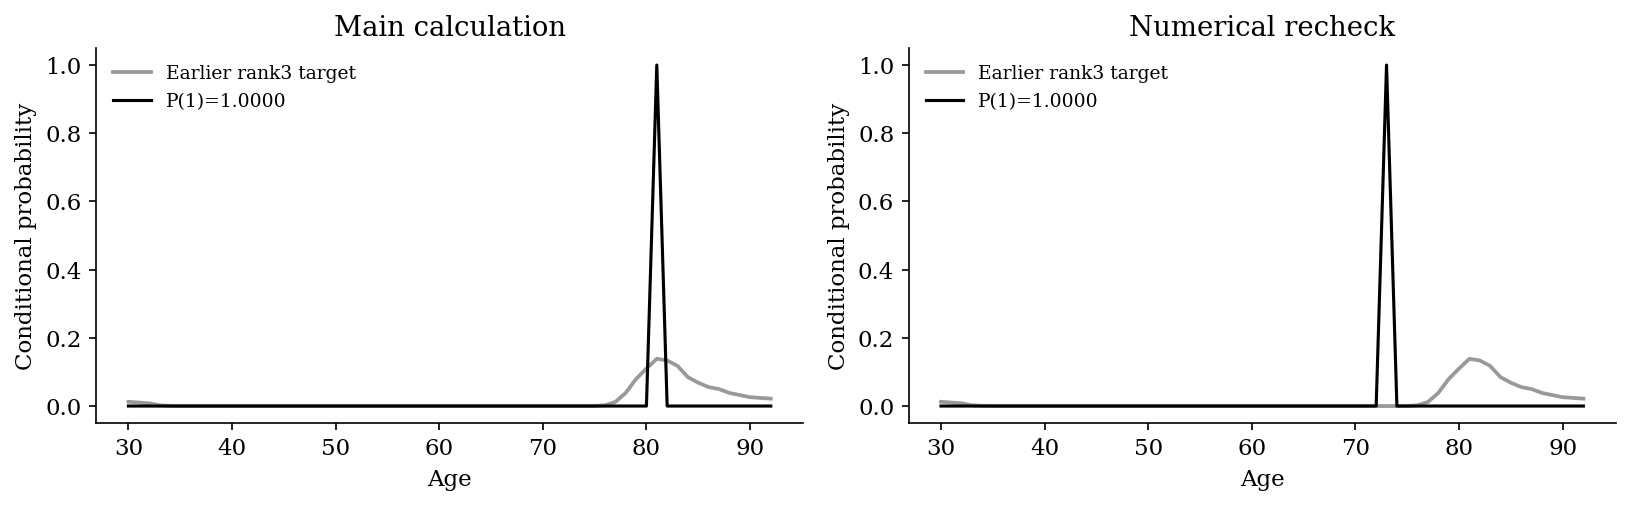

### #18: config248_p

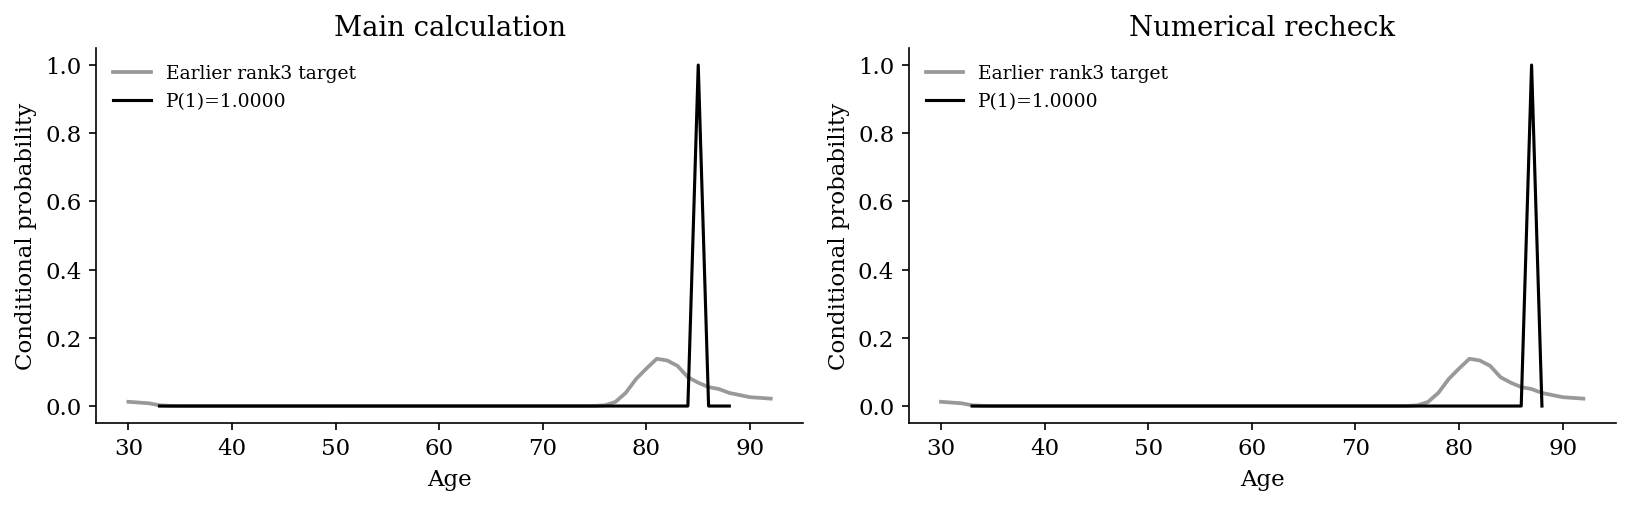

### #19: config102_n

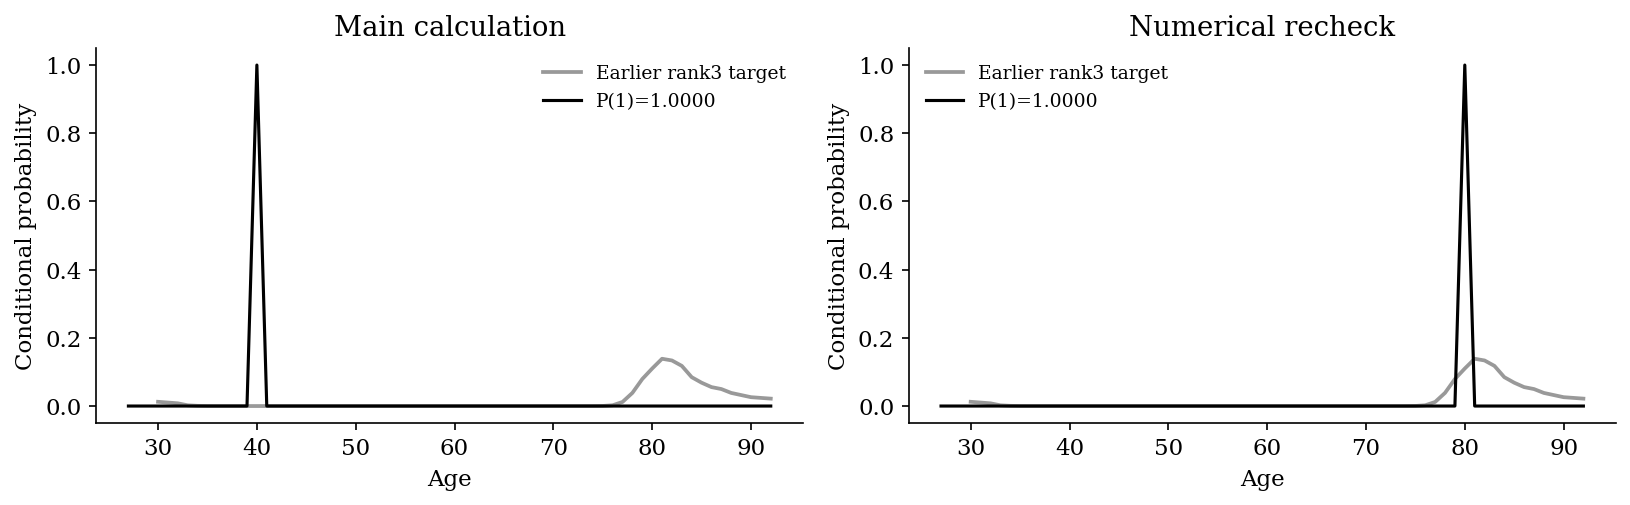

### #20: config207_n

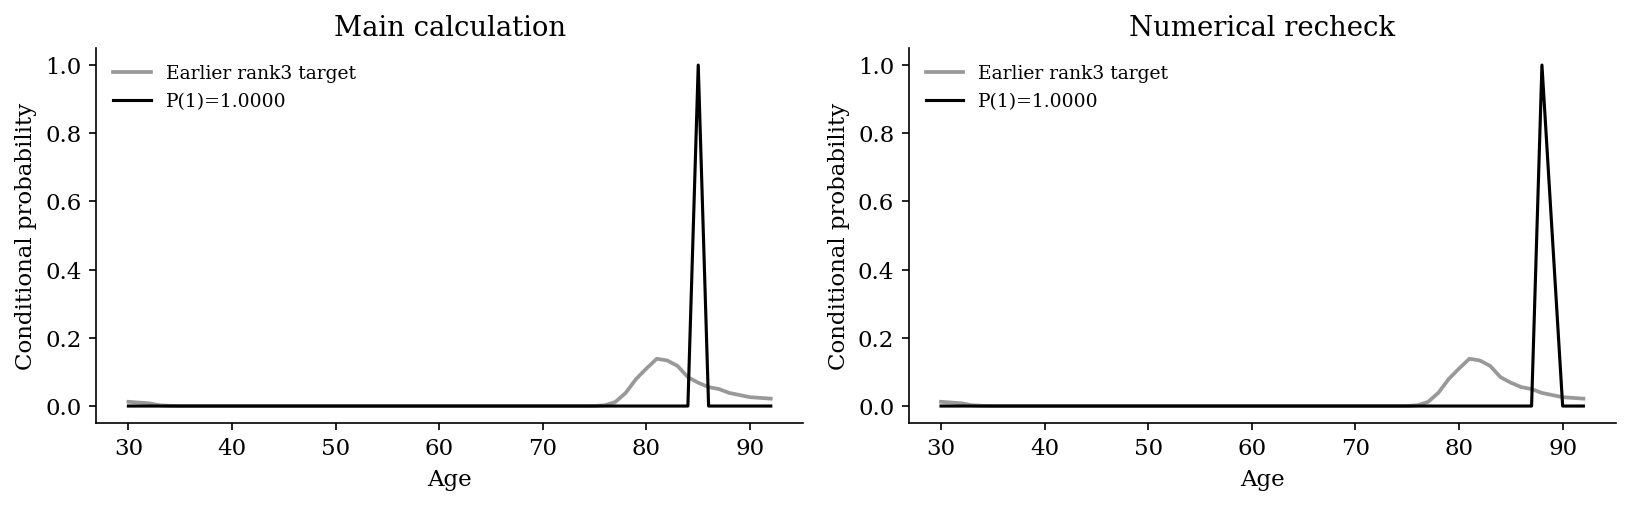

In [6]:
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
    'figure.dpi':150,'axes.spines.top':False,'axes.spines.right':False})
summary=pd.read_csv(root/'summary.csv');ranked=pd.read_csv(root/'ranked.csv')
print('All tested outcomes:');display(summary)
print('Top20:');display(ranked.head(20).style.hide(axis='index').format(precision=5))
print('Errors/non-evaluable settings:');display(json.loads((root/'errors.json').read_text()))
target=pickle.load((BASE/'scenario_100_100_q10_seed123.pkl').open('rb'))
def load_result(path,ident):
    saved=pickle.load(open(path,'rb'))
    return next(r for r in saved['results'] if r['id']==ident) if 'results' in saved else saved
for row in ranked.head(20).itertuples():
    a=load_result(row.checkpoint,row.id);b=load_result(row.check_checkpoint,row.id)
    display(Markdown(f'### #{row.rank}: {row.id}'))
    fig,axes=plt.subplots(1,2,figsize=(11,3.5))
    for ax,r,label in zip(axes,(a,b),('Main calculation','Numerical recheck')):
        ax.plot(target['ages'],target['conditional'],color='.6',lw=1.8,label='Earlier rank3 target')
        ax.plot(r['ages'],r['conditional'],color='black',lw=1.5,label=f"P(1)={r['P_1']:.4f}")
        ax.set(xlabel='Age',ylabel='Conditional probability',title=label)
        ax.legend(frameon=False,fontsize=9)
    fig.tight_layout();plt.show()


Paired comparison, same model configuration and normalization (screening results):


,id,denominator_whole,P_1_whole,P_1_segmented,correlation_whole,correlation_segmented,TV_to_rank3_whole,TV_to_rank3_segmented,TV_improvement_from_segmenting
0,config000_n,n,1.000000,1.000000,0.925832,-0.000110,0.976744,1.000000,-2.325631e-02
1,config000_p,p,1.000000,1.000000,0.925832,-0.000110,0.976744,1.000000,-2.325631e-02
2,config001_n,n,1.000000,1.000000,0.925832,-0.000110,0.976756,1.000000,-2.324402e-02
3,config001_p,p,1.000000,1.000000,0.925832,-0.000110,0.994071,1.000000,-5.928938e-03
4,config002_n,n,1.000000,1.000000,0.925832,-0.000110,0.979115,1.000000,-2.088496e-02
...,...,...,...,...,...,...,...,...,...
667,config333_p,p,1.000000,1.000000,0.962890,0.287199,1.000000,1.000000,-4.145026e-07
668,config334_n,n,0.905182,1.000000,0.954674,0.412392,0.956323,0.997167,-4.084372e-02
669,config334_p,p,0.999985,1.000000,0.954674,0.412392,0.996504,0.997167,-6.625743e-04
670,config335_n,n,0.453171,0.998306,0.945568,0.371399,0.745009,0.995777,-2.507672e-01


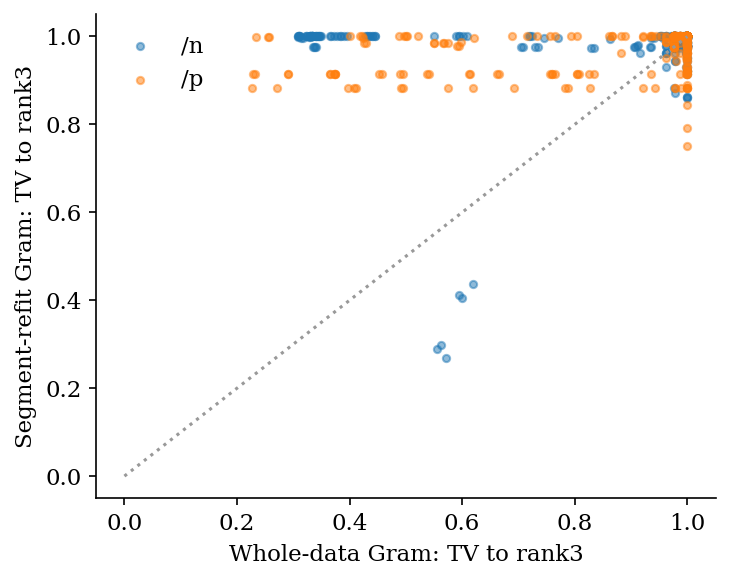

In [7]:
paired_path=root/'paired_whole_vs_segmented.csv'
if paired_path.exists():
    paired=pd.read_csv(paired_path)
    paired['TV_improvement_from_segmenting']=paired.TV_to_rank3_whole-paired.TV_to_rank3_segmented
    print('Paired comparison, same model configuration and normalization (screening results):')
    display(paired[['id','denominator_whole','P_1_whole','P_1_segmented','correlation_whole',
        'correlation_segmented','TV_to_rank3_whole','TV_to_rank3_segmented','TV_improvement_from_segmenting']])
    fig,ax=plt.subplots(figsize=(5,4))
    for divisor,g in paired.groupby('denominator_whole'):
        ax.scatter(g.TV_to_rank3_whole,g.TV_to_rank3_segmented,s=12,alpha=.5,label='/'+divisor)
    ax.plot([0,1],[0,1],color='.6',ls=':')
    ax.set(xlabel='Whole-data Gram: TV to rank3',ylabel='Segment-refit Gram: TV to rank3')
    ax.legend(frameon=False);fig.tight_layout();plt.show()


In [8]:
unbalanced=pd.read_csv(unbalanced_root/'summary.csv')
balanced=pd.read_csv(root/'summary.csv')
paired=unbalanced.merge(balanced,on='id',suffixes=('_unbalanced','_balanced'))
paired.to_csv(root/'paired_balanced_vs_unbalanced.csv',index=False)
display(paired[['id','P_1_unbalanced','P_1_balanced','TV_to_rank3_unbalanced','TV_to_rank3_balanced','correlation_unbalanced','correlation_balanced']])

,id,P_1_unbalanced,P_1_balanced,TV_to_rank3_unbalanced,TV_to_rank3_balanced,correlation_unbalanced,correlation_balanced
0,config000_n,1.000000,1.000000,0.999980,1.000000,-0.000184,-0.000110
1,config000_p,1.000000,1.000000,1.000000,1.000000,-0.000184,-0.000110
2,config001_n,1.000000,1.000000,0.999998,1.000000,-0.000184,-0.000110
3,config001_p,1.000000,1.000000,1.000000,1.000000,-0.000184,-0.000110
4,config002_n,1.000000,1.000000,0.999998,1.000000,-0.000184,-0.000110
...,...,...,...,...,...,...,...
667,config333_p,1.000000,1.000000,1.000000,1.000000,0.282617,0.287199
668,config334_n,1.000000,1.000000,0.999973,0.997167,0.397644,0.412392
669,config334_p,1.000000,1.000000,1.000000,0.997167,0.397644,0.412392
670,config335_n,0.519200,0.998306,0.764511,0.995777,0.358144,0.371399


## Top 20 unpenalized results — logistic auxiliary/segment fits preferred

Completed **unbalanced segmented Gram** study. Restrict to zero explicit L1/L2 penalty; prioritize logistic auxiliary and segment refits, then rank by smallest screening TV distance to the earlier rank-3 curve. There are 216 logistic candidates, so all twenty selected rows use logistic. Finite iteration budgets act as implicit regularization. The solver, budget and intercept choice are matched across the initial auxiliary, segment and posterior regressions. No P(1) cutoff is imposed; probabilities are displayed rather than optimized. Screening uses 512 draws; existing 1024-draw rechecks are overlaid and tabulated where available. Missing rechecks are explicitly marked. This is exploratory shape-based selection, not evidence of statistical calibration.

Logistic auxiliary/segment fits prioritized; within each loss, ascending screening TV. No P(1) threshold.


subset_rank,id,P_1,TV_to_rank3,aux_loss,penalty,strength,method,budget,intercept,Delta,denominator,correlation,peak_age,mass_above55,recheck_count,recheck_P1_min,recheck_P1_max
1,config143_n,1.00000,0.74862,logistic,none,0.00000,fista,30,False,2,n,0.08374,83.00000,1.00000,2,1.00000,1.00000
2,config045_n,1.00000,0.81081,logistic,none,0.00000,gd,100,False,1,n,0.05149,79.00000,1.00000,2,1.00000,1.00000
3,config031_p,1.00000,0.86136,logistic,none,0.00000,fista,30,False,1,p,0.08374,81.00000,1.00000,0,Not rechecked,Not rechecked
4,config045_p,1.00000,0.86136,logistic,none,0.00000,gd,100,False,1,p,0.05149,81.00000,1.00000,0,Not rechecked,Not rechecked
5,config143_p,1.00000,0.86136,logistic,none,0.00000,fista,30,False,2,p,0.08374,81.00000,1.00000,2,1.00000,1.00000
6,config157_p,1.00000,0.86136,logistic,none,0.00000,gd,100,False,2,p,0.05149,81.00000,1.00000,2,1.00000,1.00000
7,config317_p,1.00000,0.86136,logistic,none,0.00000,lbfgs,30,True,5,p,0.07909,81.00000,1.00000,0,Not rechecked,Not rechecked
8,config255_n,1.00000,0.86556,logistic,none,0.00000,fista,30,False,5,n,0.08374,82.00000,1.00000,0,Not rechecked,Not rechecked
9,config031_n,1.00000,0.88226,logistic,none,0.00000,fista,30,False,1,n,0.08374,83.00000,1.00000,0,Not rechecked,Not rechecked
10,config150_n,1.00000,0.88227,logistic,none,0.00000,lbfgs,50,False,2,n,0.13992,83.00000,1.00000,0,Not rechecked,Not rechecked


### Unpenalized #1: config143_n
Screening P(1)=1.0000; TV=0.7486; correlation=0.0837.

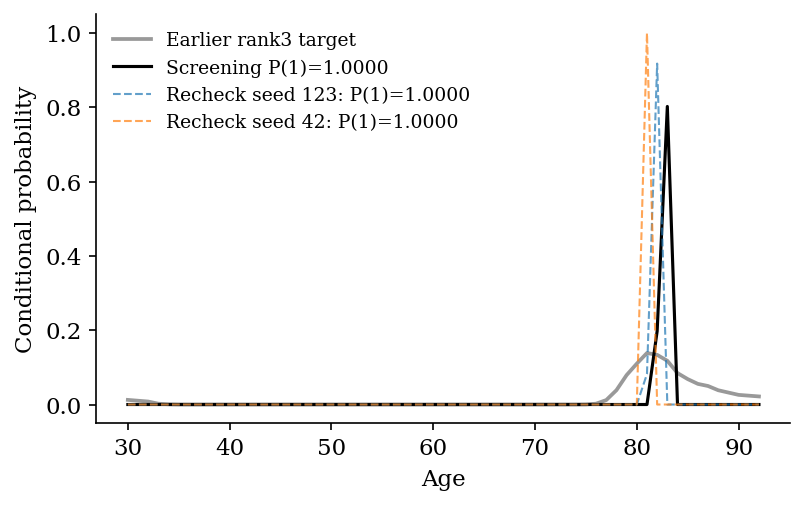

### Unpenalized #2: config045_n
Screening P(1)=1.0000; TV=0.8108; correlation=0.0515.

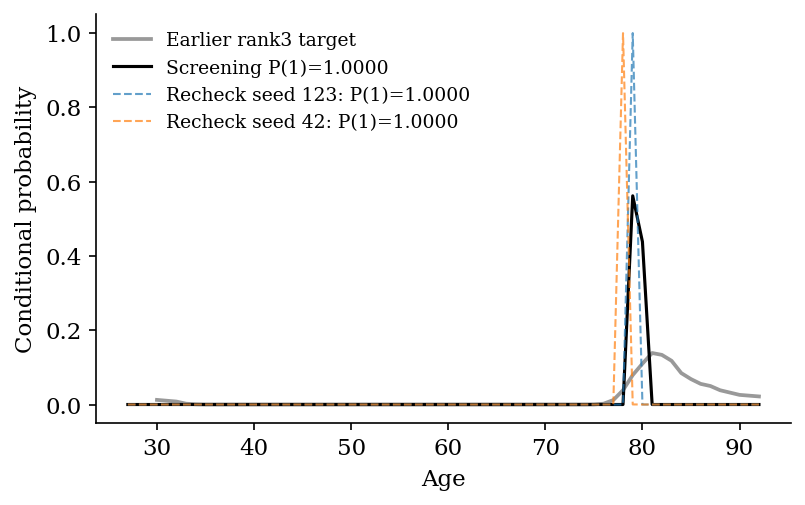

### Unpenalized #3: config031_p
Screening P(1)=1.0000; TV=0.8614; correlation=0.0837.

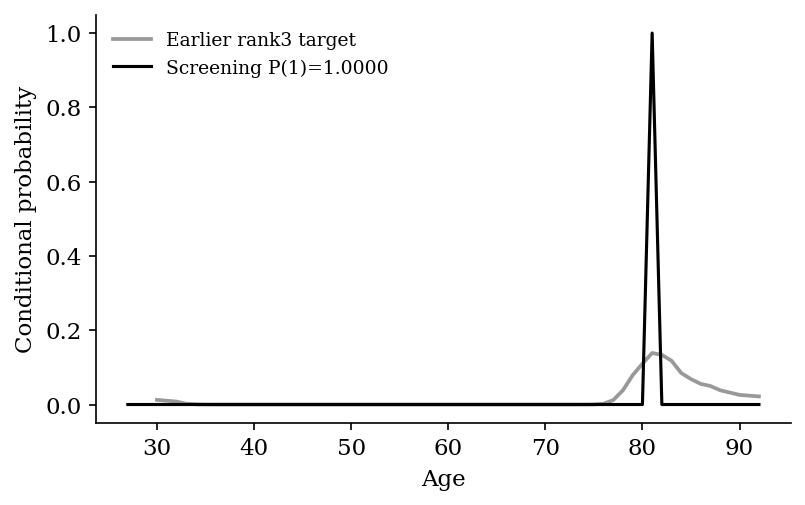

### Unpenalized #4: config045_p
Screening P(1)=1.0000; TV=0.8614; correlation=0.0515.

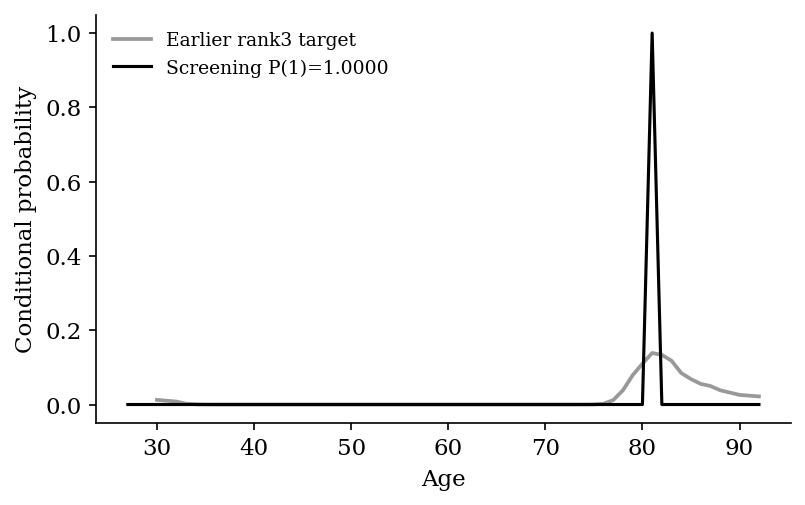

### Unpenalized #5: config143_p
Screening P(1)=1.0000; TV=0.8614; correlation=0.0837.

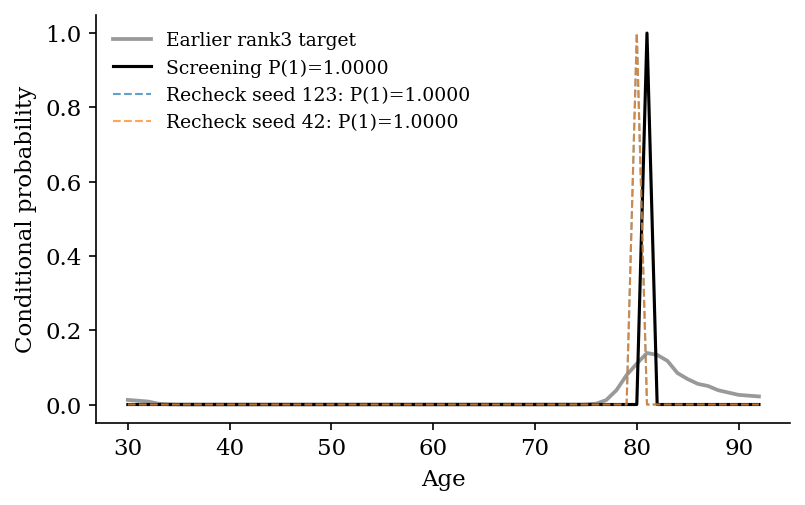

### Unpenalized #6: config157_p
Screening P(1)=1.0000; TV=0.8614; correlation=0.0515.

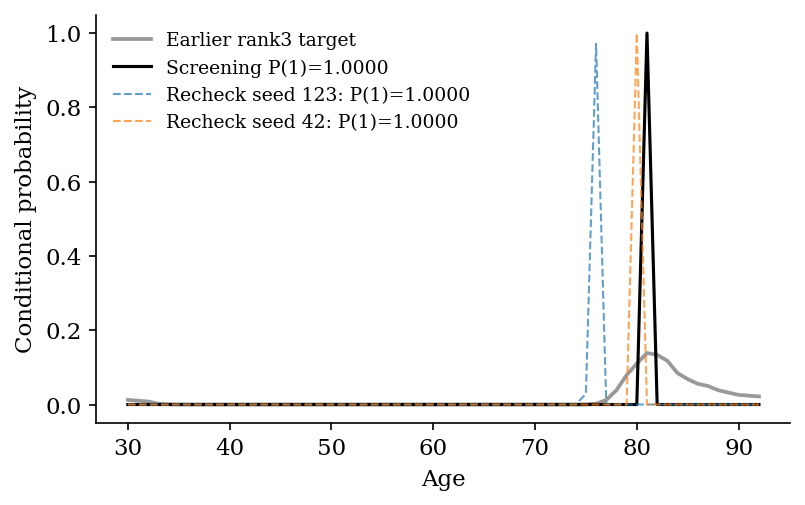

### Unpenalized #7: config317_p
Screening P(1)=1.0000; TV=0.8614; correlation=0.0791.

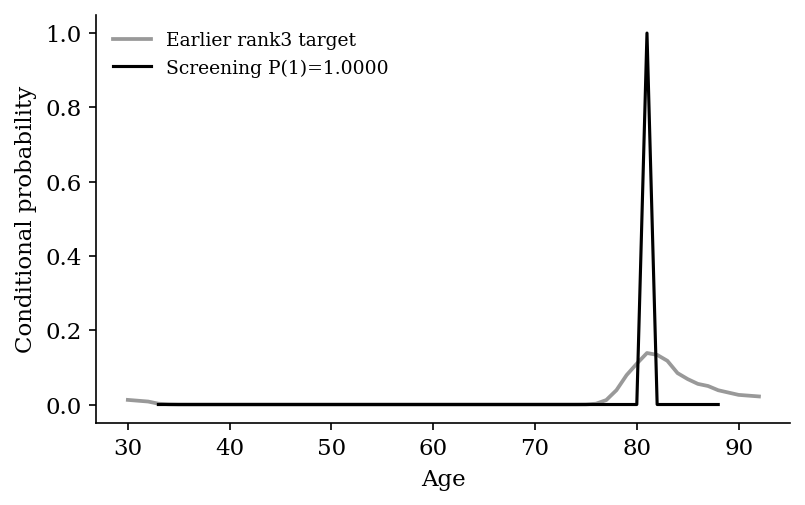

### Unpenalized #8: config255_n
Screening P(1)=1.0000; TV=0.8656; correlation=0.0837.

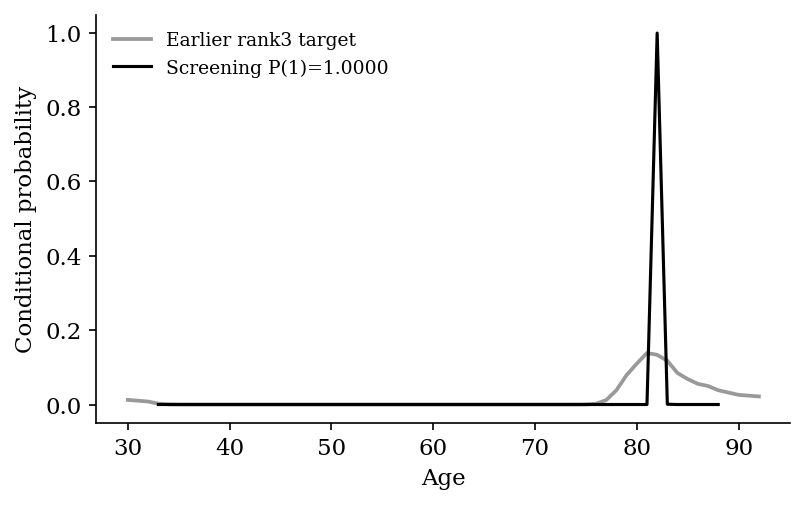

### Unpenalized #9: config031_n
Screening P(1)=1.0000; TV=0.8823; correlation=0.0837.

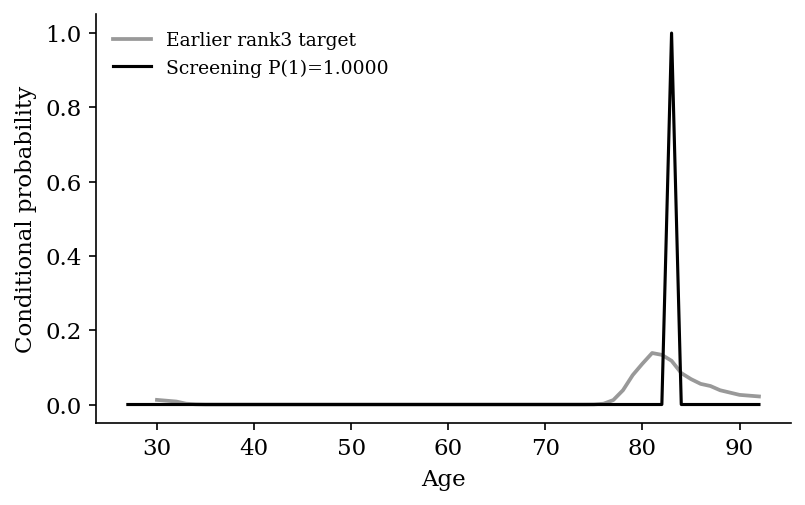

### Unpenalized #10: config150_n
Screening P(1)=1.0000; TV=0.8823; correlation=0.1399.

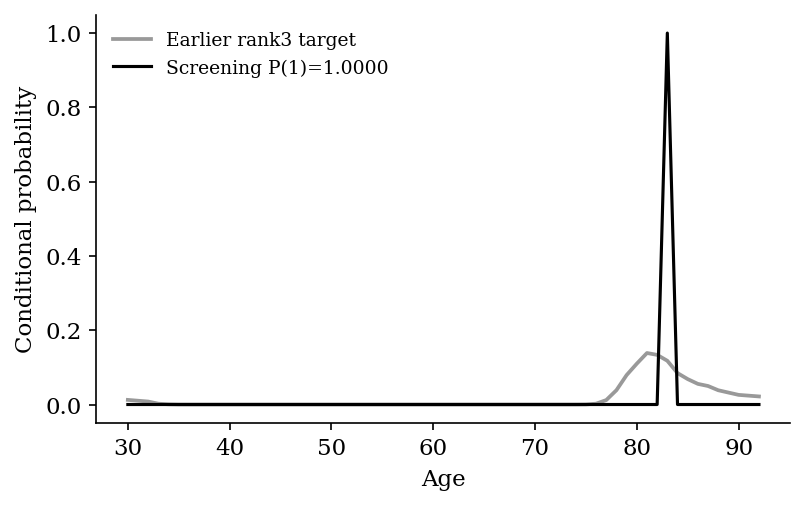

### Unpenalized #11: config262_p
Screening P(1)=1.0000; TV=0.8823; correlation=0.1399.

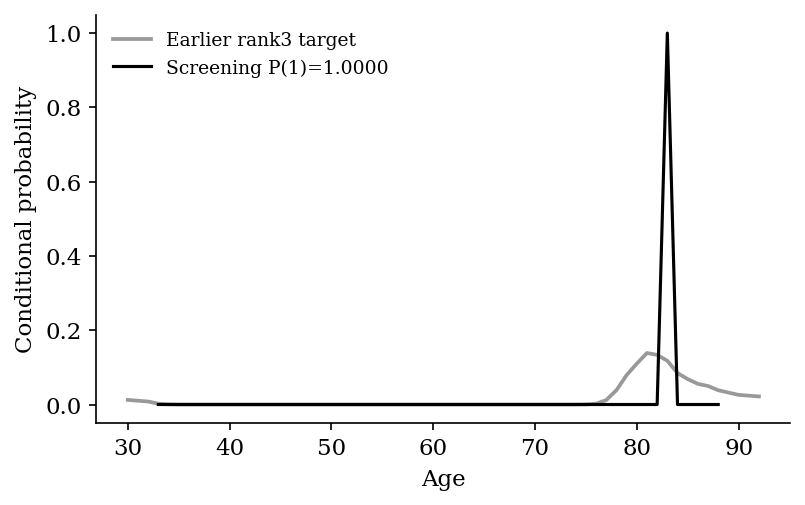

### Unpenalized #12: config255_p
Screening P(1)=1.0000; TV=0.8894; correlation=0.0837.

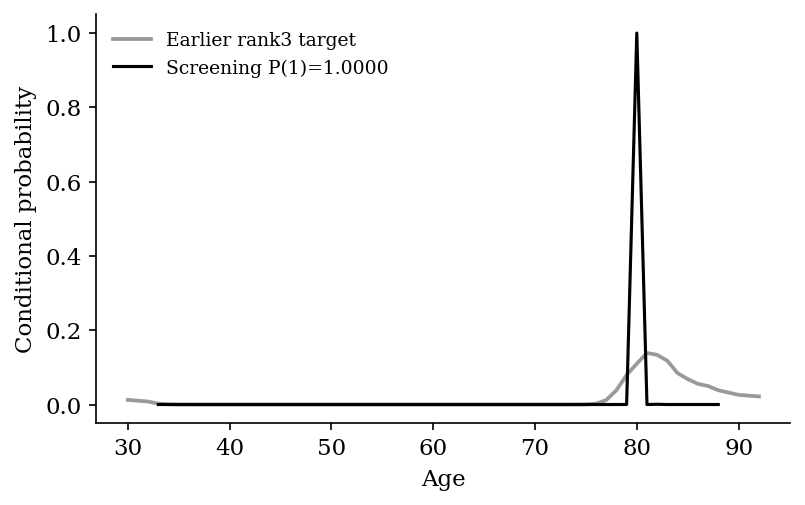

### Unpenalized #13: config157_n
Screening P(1)=1.0000; TV=0.9146; correlation=0.0515.

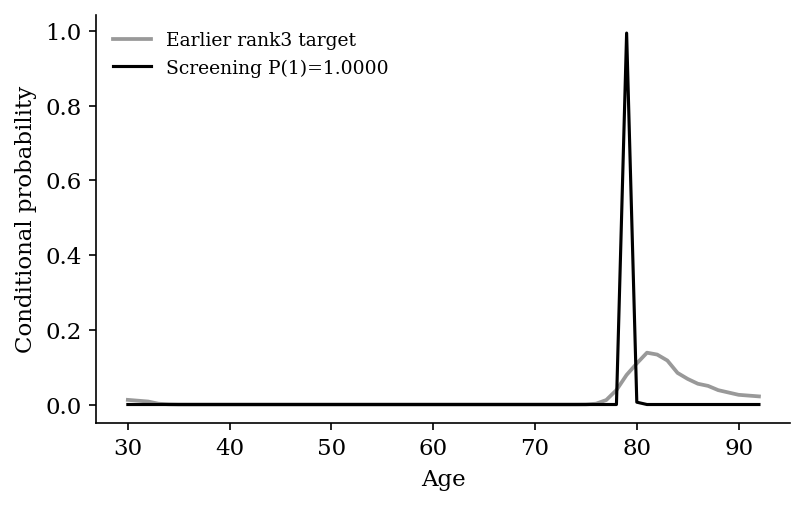

### Unpenalized #14: config262_n
Screening P(1)=1.0000; TV=0.9154; correlation=0.1399.

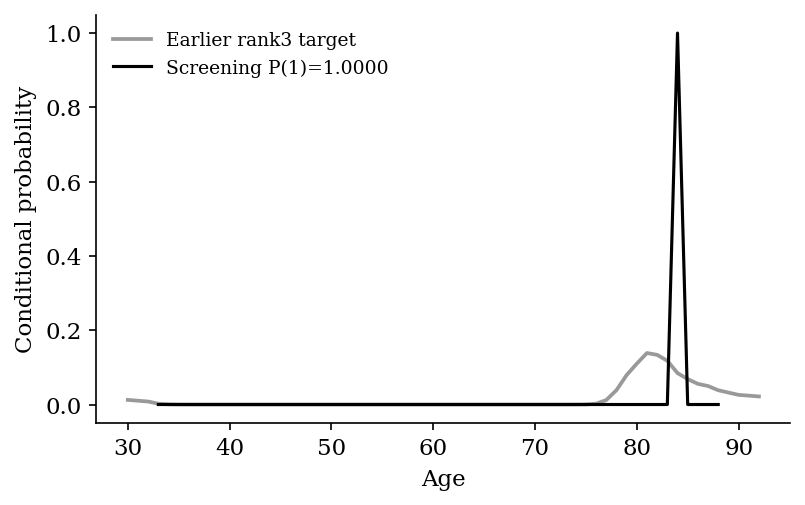

### Unpenalized #15: config269_n
Screening P(1)=1.0000; TV=0.9207; correlation=0.0515.

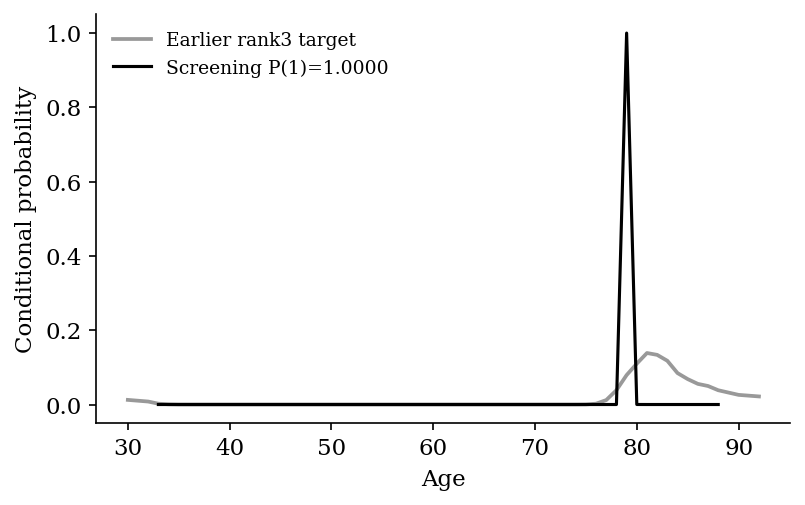

### Unpenalized #16: config037_p
Screening P(1)=1.0000; TV=0.9208; correlation=0.1734.

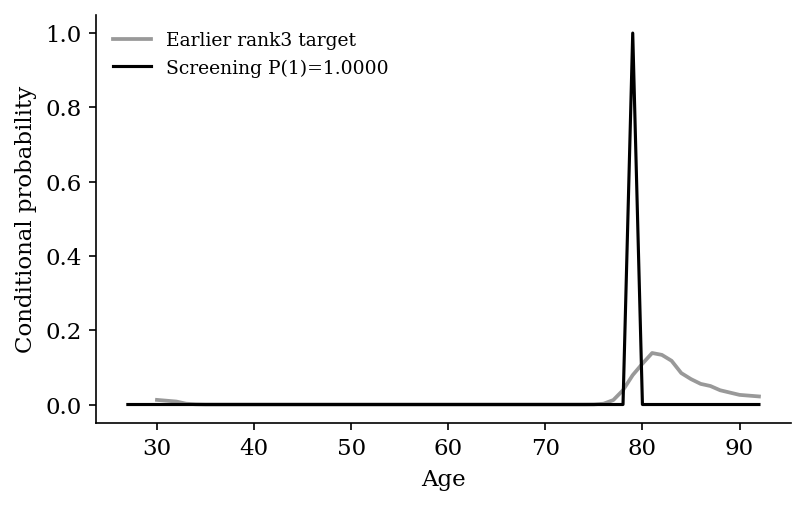

### Unpenalized #17: config038_n
Screening P(1)=1.0000; TV=0.9316; correlation=0.1399.

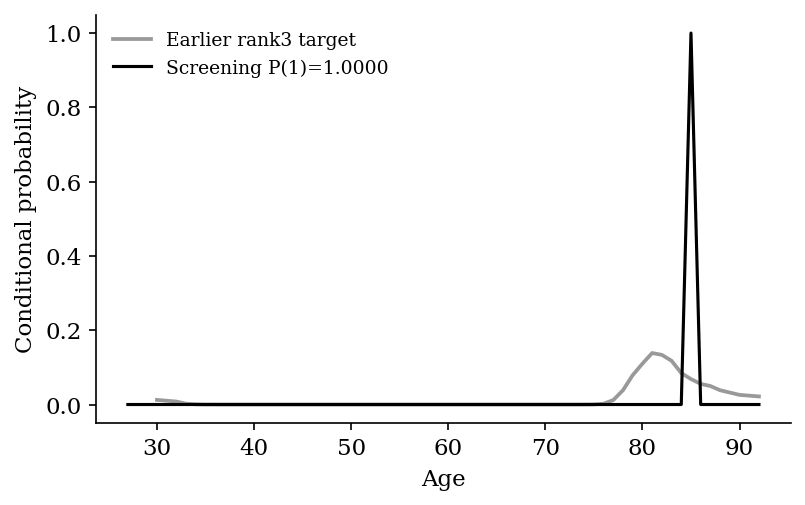

### Unpenalized #18: config094_p
Screening P(1)=1.0000; TV=0.9445; correlation=0.0379.

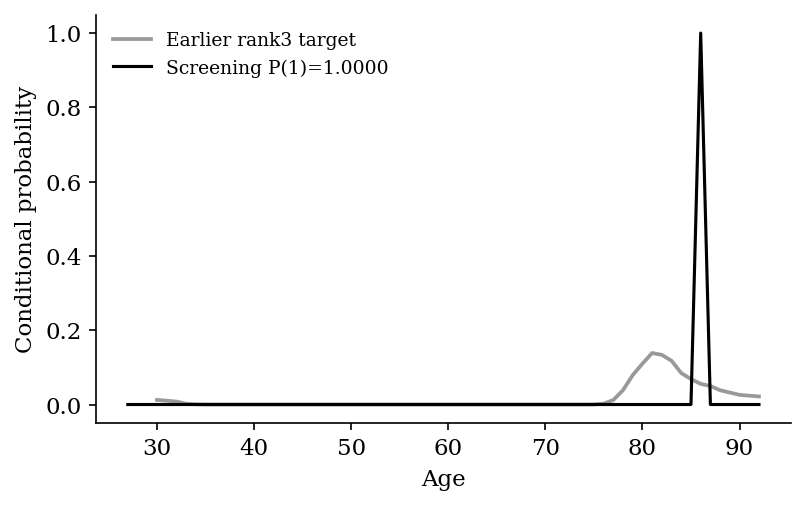

### Unpenalized #19: config257_n
Screening P(1)=1.0000; TV=0.9445; correlation=0.1829.

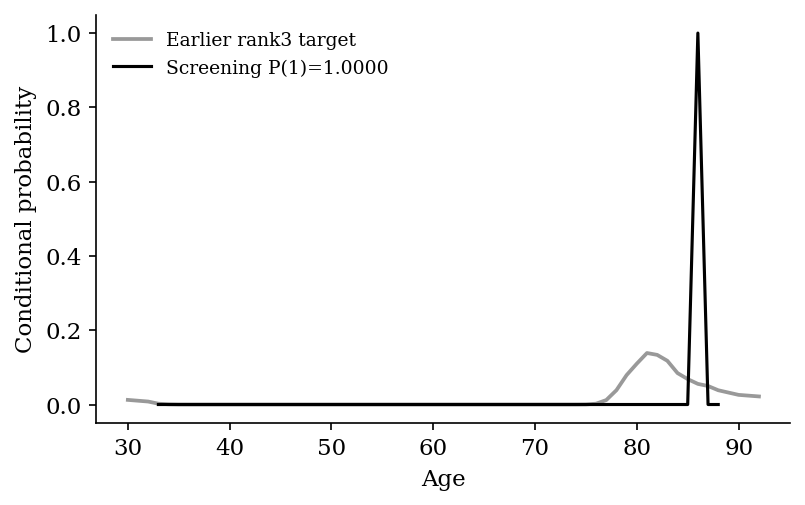

### Unpenalized #20: config319_p
Screening P(1)=1.0000; TV=0.9445; correlation=0.0234.

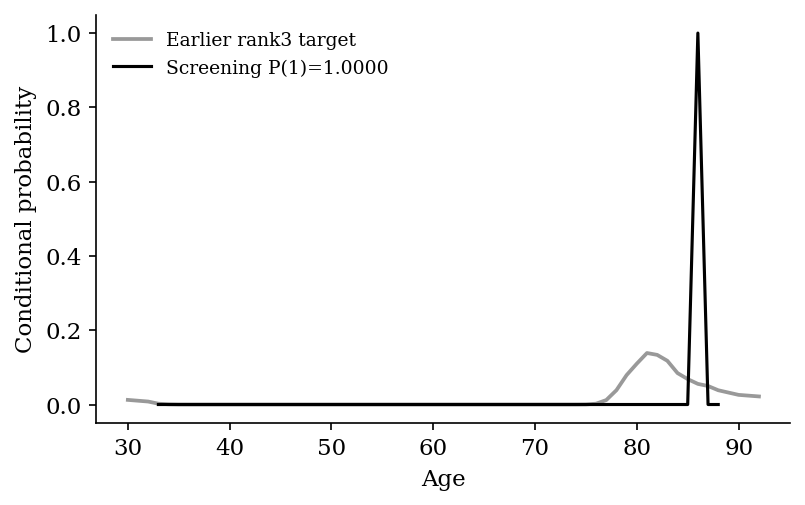

In [1]:

from pathlib import Path
import pickle
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
root=Path('results/myocardial_gram_pair_1ce06b10b4f5/segmented')
summary=pd.read_csv(root/'summary.csv')
unpenalized=summary.loc[summary.penalty=='none'].copy()
unpenalized['loss_priority']=(unpenalized.aux_loss!='logistic').astype(int)
selected=unpenalized.sort_values(['loss_priority','TV_to_rank3','id']).head(20).copy()
assert len(selected)==20 and selected.penalty.eq('none').all()
print('Logistic auxiliary/segment fits prioritized; within each loss, ascending screening TV. No P(1) threshold.')
selected.insert(0,'subset_rank',range(1,len(selected)+1))
validation=pd.read_csv(root/'validation.csv')
checks=validation.groupby('id').agg(recheck_P1_min=('P_1','min'),recheck_P1_max=('P_1','max'),recheck_count=('P_1','size'))
selected=selected.merge(checks,left_on='id',right_index=True,how='left')
selected['recheck_count']=selected.recheck_count.fillna(0).astype(int)
cols=['subset_rank','id','P_1','TV_to_rank3','aux_loss','penalty','strength','method','budget','intercept','Delta','denominator','correlation','peak_age','mass_above55','recheck_count','recheck_P1_min','recheck_P1_max']
display(selected[cols].style.hide(axis='index').format(precision=5,na_rep='Not rechecked'))
target=pickle.load(open('results/myocardial_final_redo_e3d965cc4b9b/scenario_100_100_q10_seed123.pkl','rb'))
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
    'figure.dpi':150,'axes.spines.top':False,'axes.spines.right':False})
for row in selected.itertuples():
    result=pickle.load(open(row.checkpoint,'rb'))
    display(Markdown(f'### Unpenalized #{row.subset_rank}: {row.id}\n'
        f'Screening P(1)={row.P_1:.4f}; TV={row.TV_to_rank3:.4f}; correlation={row.correlation:.4f}.'))
    fig,ax=plt.subplots(figsize=(5.5,3.5))
    ax.plot(target['ages'],target['conditional'],color='.6',lw=1.8,label='Earlier rank3 target')
    ax.plot(result['ages'],result['conditional'],color='black',lw=1.5,label=f'Screening P(1)={row.P_1:.4f}')
    for check in validation.loc[validation.id==row.id].itertuples():
        checked=pickle.load(open(check.checkpoint,'rb'))
        ax.plot(checked['ages'],checked['conditional'],lw=1,ls='--',alpha=.7,label=f'Recheck seed {check.seed}: P(1)={check.P_1:.4f}')
    ax.set(xlabel='Age',ylabel='Conditional probability')
    ax.legend(frameon=False,fontsize=9);fig.tight_layout();plt.show()


## Top 20 unpenalized least-squares auxiliary/segment results

Completed **unbalanced segmented Gram** study. Both the initial auxiliary fit and the estimated-segment refits use exact, unpenalized least squares. The posterior WERM regression uses unpenalized finite-iteration logistic; the displayed solver and iteration budget refer to that logistic fit, not to LS. Select the twenty smallest **512-draw screening TV distances** to the earlier rank-3 curve, with no P(1) cutoff. All these LS screening configurations have P(1) numerically near one; that is not evidence of calibration. Available 1024-draw rechecks are tabulated and overlaid, and missing checks are explicitly marked. The best screening candidate had TV about 0.890, worsening to about 1.000 on recheck; the ranking must not be interpreted as a validated good match.

subset_rank,id,P_1,TV_to_rank3,aux_loss,penalty,strength,method,budget,intercept,Delta,denominator,correlation,peak_age,mass_above55,recheck_count,recheck_P1_min,recheck_P1_max
1,config226_p,1.00000,0.89002,squared,none,0.00000,fista,20,False,5,p,-0.00018,80.00000,1.00000,2,1.00000,1.00000
2,config114_p,1.00000,0.93157,squared,none,0.00000,fista,20,False,2,p,-0.00018,85.00000,1.00000,2,1.00000,1.00000
3,config003_p,1.00000,0.93157,squared,none,0.00000,fista,30,False,1,p,-0.00018,85.00000,1.00000,0,Not rechecked,Not rechecked
4,config115_p,1.00000,0.93157,squared,none,0.00000,fista,30,False,2,p,-0.00018,85.00000,1.00000,0,Not rechecked,Not rechecked
5,config129_p,1.00000,0.93157,squared,none,0.00000,gd,100,False,2,p,-0.00018,85.00000,1.00000,0,Not rechecked,Not rechecked
6,config227_p,1.00000,0.93157,squared,none,0.00000,fista,30,False,5,p,-0.00018,85.00000,1.00000,0,Not rechecked,Not rechecked
7,config241_p,1.00000,0.93157,squared,none,0.00000,gd,100,False,5,p,-0.00018,85.00000,1.00000,0,Not rechecked,Not rechecked
8,config230_p,1.00000,0.94566,squared,none,0.00000,lbfgs,8,False,5,p,-0.00018,87.00000,1.00000,0,Not rechecked,Not rechecked
9,config116_p,1.00000,0.95018,squared,none,0.00000,fista,50,False,2,p,-0.00018,87.00000,1.00000,0,Not rechecked,Not rechecked
10,config004_p,1.00000,0.95019,squared,none,0.00000,fista,50,False,1,p,-0.00018,87.00000,1.00000,0,Not rechecked,Not rechecked


### Unpenalized LS #1: config226_p
Screening P(1)=1.0000; TV=0.8900; correlation=-0.0002.

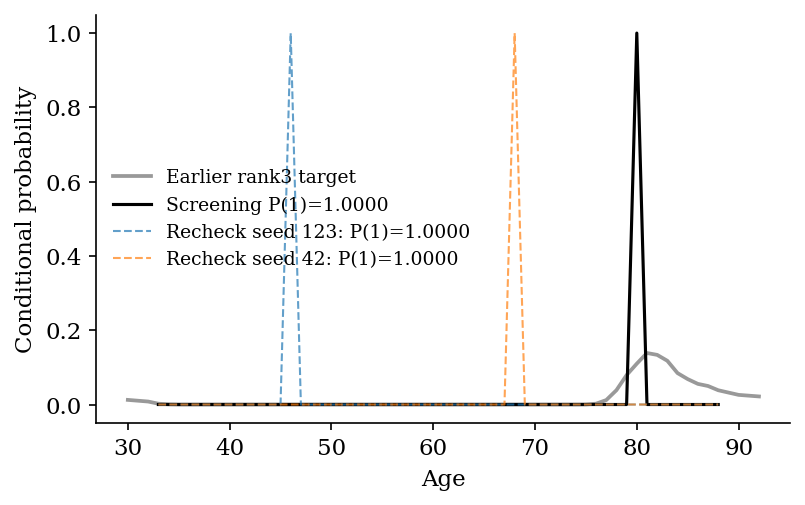

### Unpenalized LS #2: config114_p
Screening P(1)=1.0000; TV=0.9316; correlation=-0.0002.

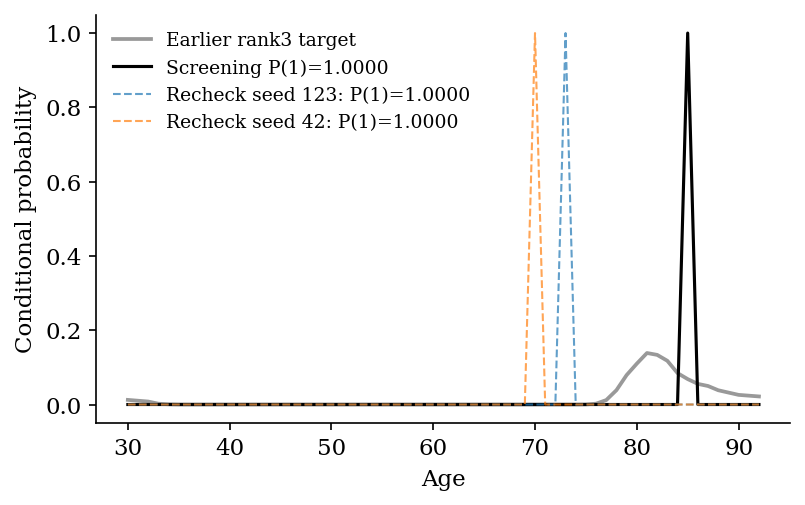

### Unpenalized LS #3: config003_p
Screening P(1)=1.0000; TV=0.9316; correlation=-0.0002.

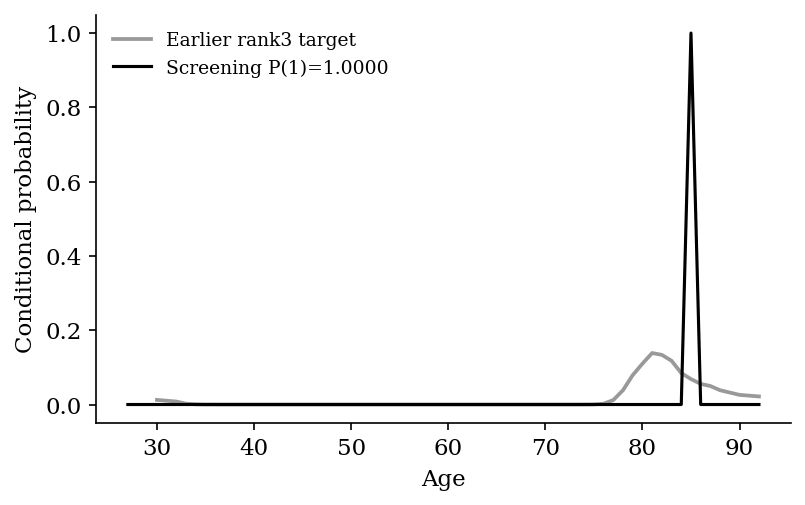

### Unpenalized LS #4: config115_p
Screening P(1)=1.0000; TV=0.9316; correlation=-0.0002.

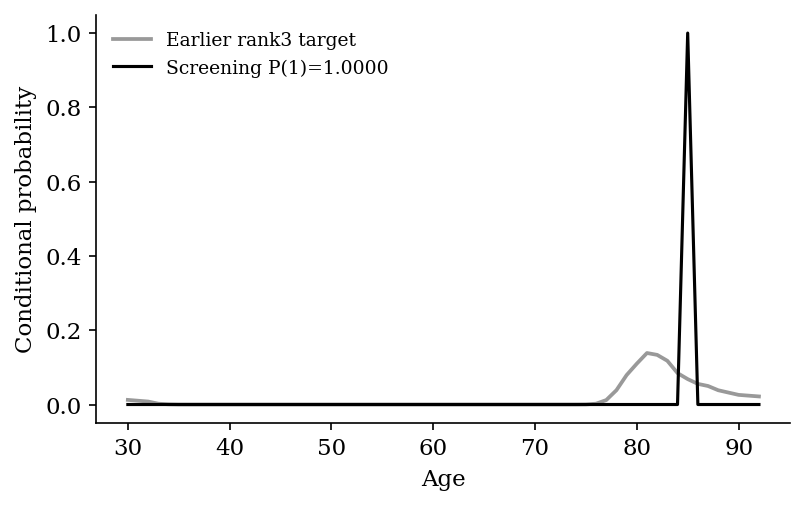

### Unpenalized LS #5: config129_p
Screening P(1)=1.0000; TV=0.9316; correlation=-0.0002.

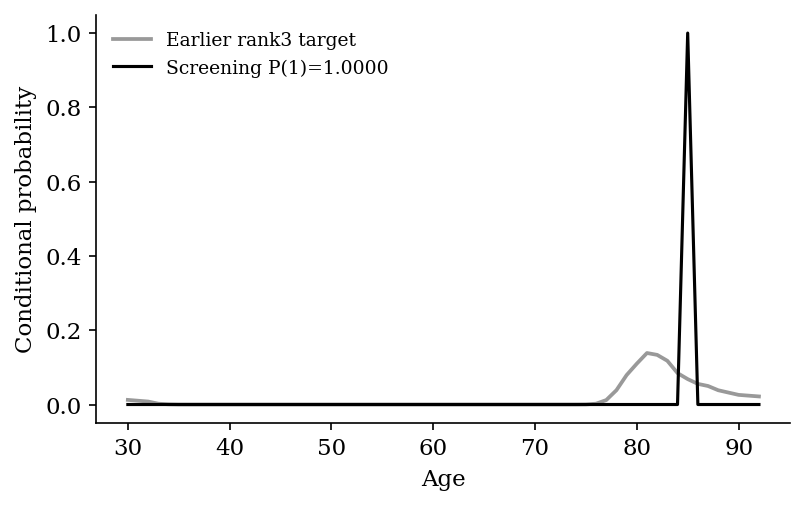

### Unpenalized LS #6: config227_p
Screening P(1)=1.0000; TV=0.9316; correlation=-0.0002.

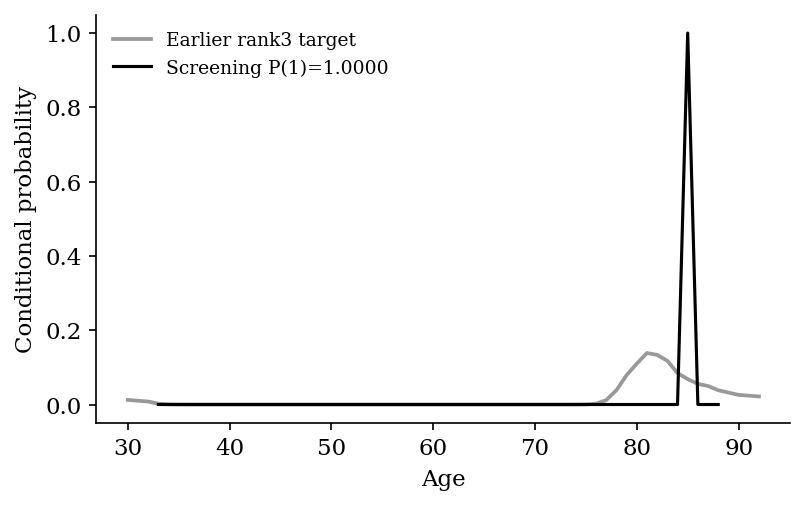

### Unpenalized LS #7: config241_p
Screening P(1)=1.0000; TV=0.9316; correlation=-0.0002.

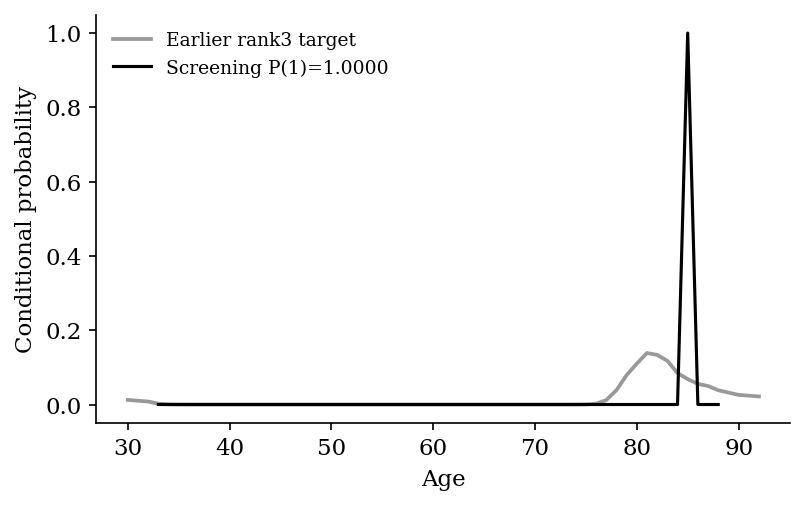

### Unpenalized LS #8: config230_p
Screening P(1)=1.0000; TV=0.9457; correlation=-0.0002.

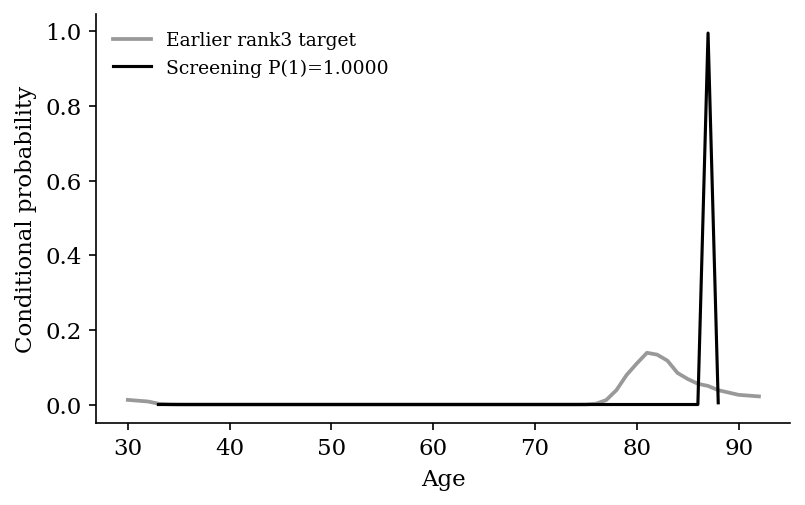

### Unpenalized LS #9: config116_p
Screening P(1)=1.0000; TV=0.9502; correlation=-0.0002.

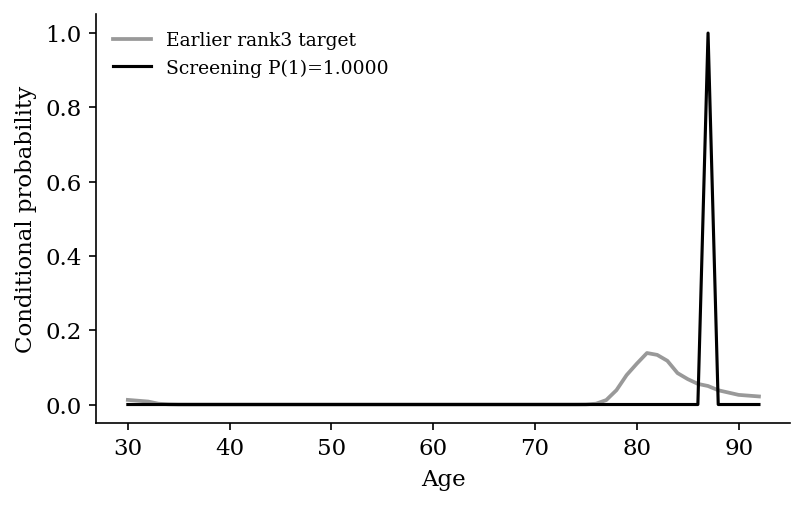

### Unpenalized LS #10: config004_p
Screening P(1)=1.0000; TV=0.9502; correlation=-0.0002.

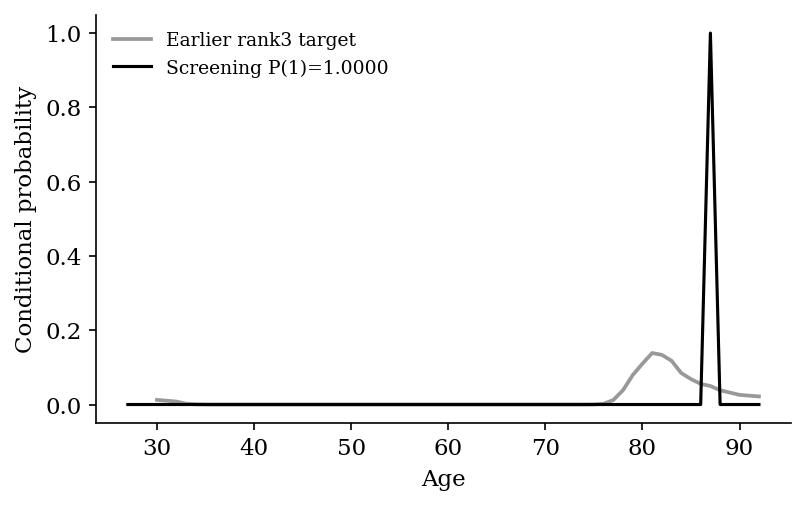

### Unpenalized LS #11: config228_p
Screening P(1)=1.0000; TV=0.9502; correlation=-0.0002.

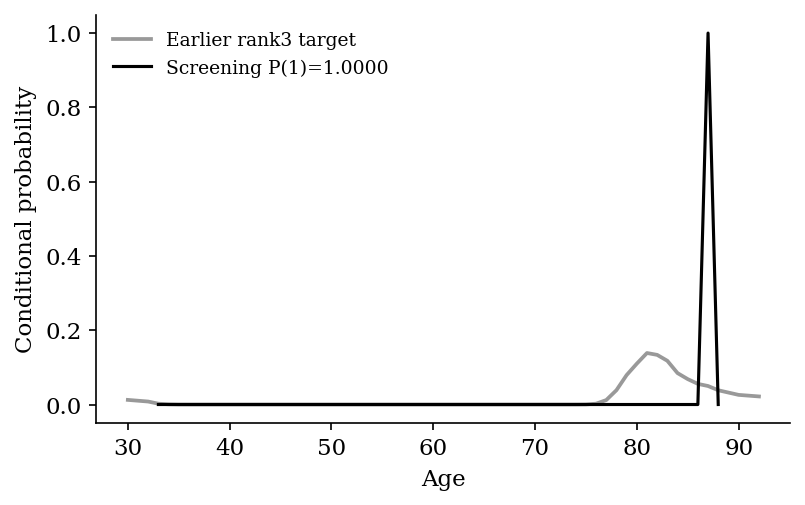

### Unpenalized LS #12: config118_p
Screening P(1)=1.0000; TV=0.9503; correlation=-0.0002.

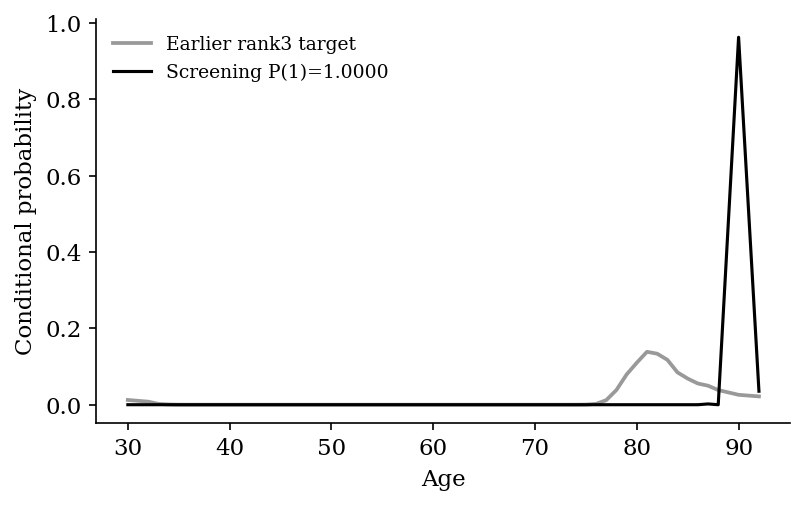

### Unpenalized LS #13: config006_p
Screening P(1)=1.0000; TV=0.9616; correlation=-0.0002.

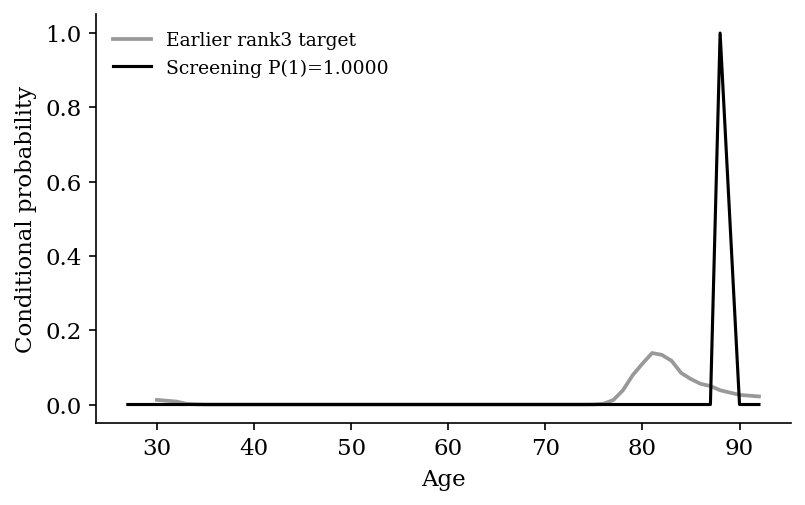

### Unpenalized LS #14: config007_p
Screening P(1)=1.0000; TV=0.9616; correlation=-0.0002.

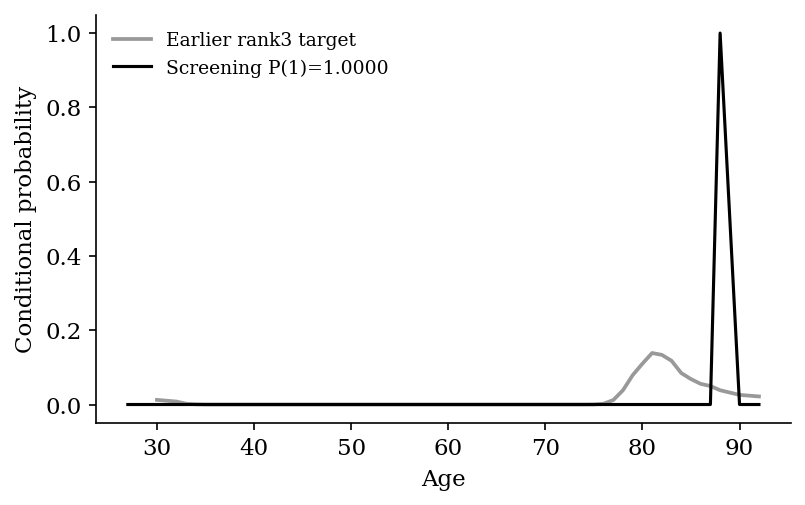

### Unpenalized LS #15: config005_p
Screening P(1)=1.0000; TV=0.9616; correlation=-0.0002.

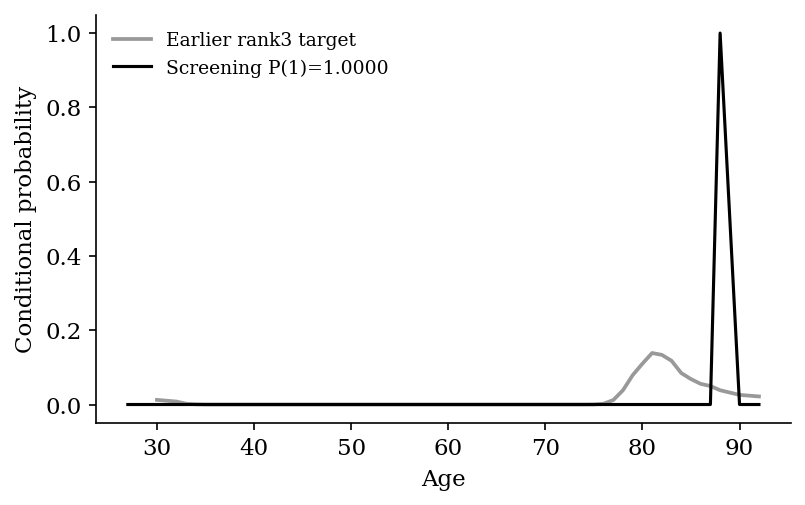

### Unpenalized LS #16: config008_p
Screening P(1)=1.0000; TV=0.9616; correlation=-0.0002.

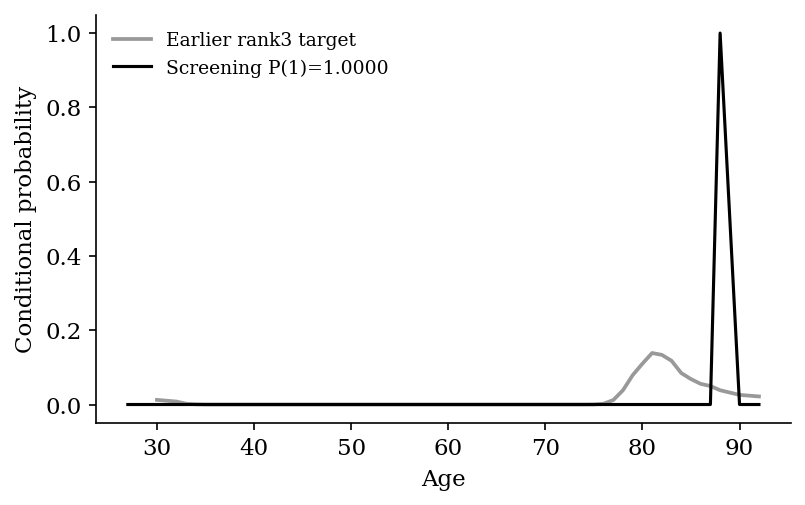

### Unpenalized LS #17: config009_p
Screening P(1)=1.0000; TV=0.9616; correlation=-0.0002.

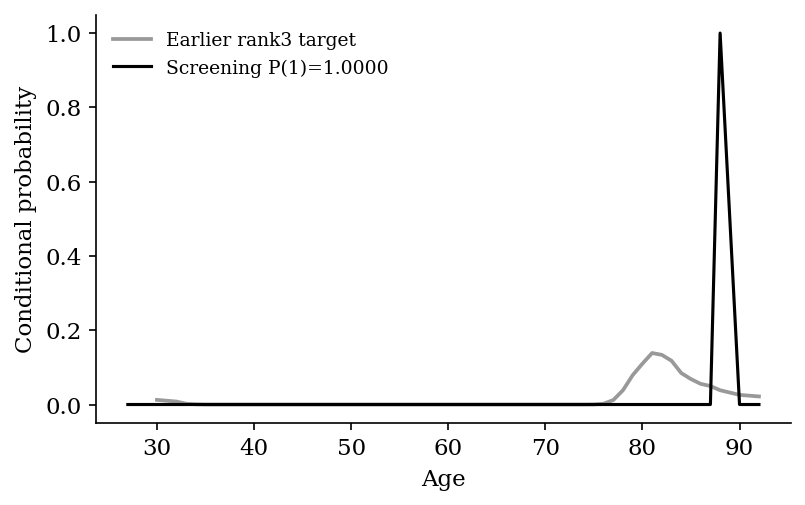

### Unpenalized LS #18: config010_p
Screening P(1)=1.0000; TV=0.9616; correlation=-0.0002.

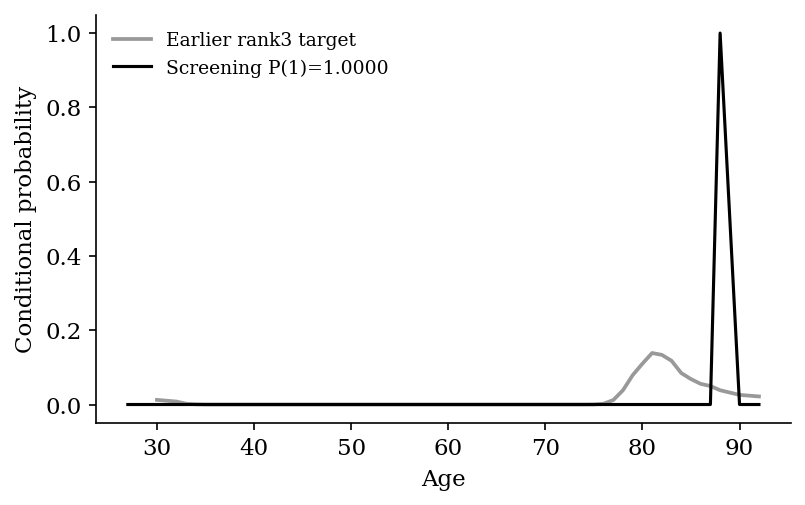

### Unpenalized LS #19: config011_p
Screening P(1)=1.0000; TV=0.9616; correlation=-0.0002.

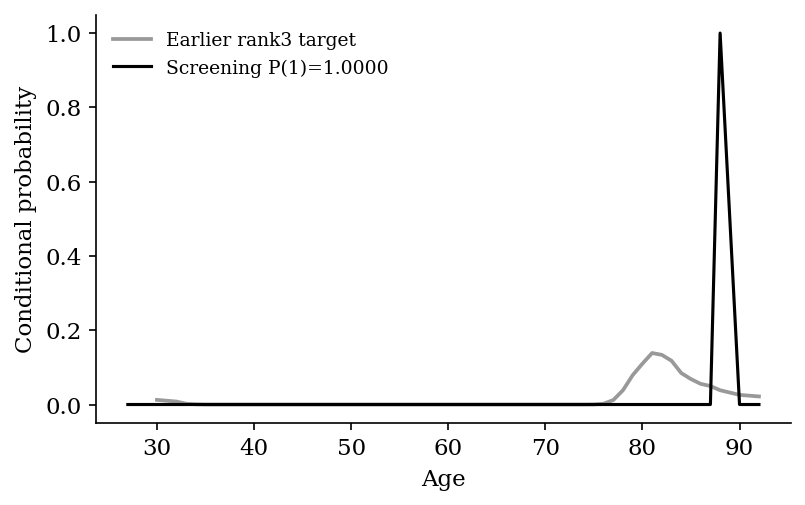

### Unpenalized LS #20: config229_p
Screening P(1)=1.0000; TV=0.9616; correlation=-0.0002.

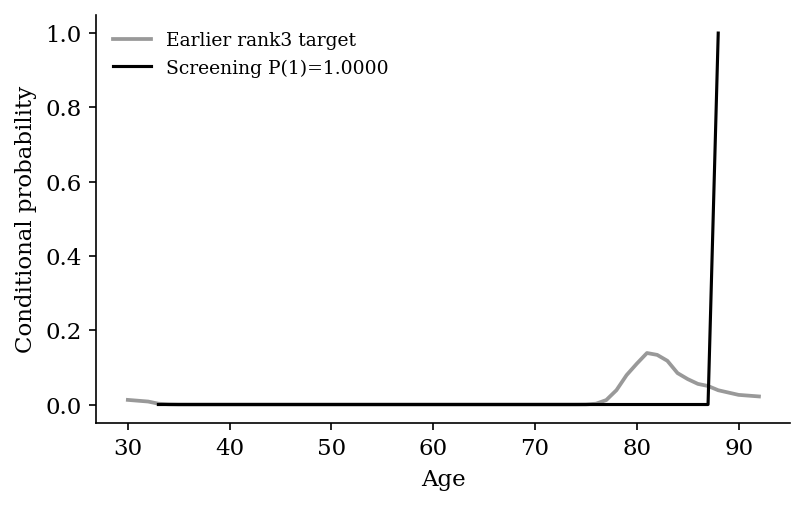

In [1]:

from pathlib import Path
import pickle
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
root=Path('results/myocardial_gram_pair_1ce06b10b4f5/segmented')
summary=pd.read_csv(root/'summary.csv')
selected=summary.loc[(summary.penalty=='none') & (summary.aux_loss=='squared')].sort_values(['TV_to_rank3','id']).head(20).copy()
assert len(selected)==20 and selected.penalty.eq('none').all() and selected.aux_loss.eq('squared').all()
selected.insert(0,'subset_rank',range(1,len(selected)+1))
validation=pd.read_csv(root/'validation.csv')
checks=validation.groupby('id').agg(recheck_P1_min=('P_1','min'),recheck_P1_max=('P_1','max'),recheck_count=('P_1','size'))
selected=selected.merge(checks,left_on='id',right_index=True,how='left')
selected['recheck_count']=selected.recheck_count.fillna(0).astype(int)
cols=['subset_rank','id','P_1','TV_to_rank3','aux_loss','penalty','strength','method','budget','intercept','Delta','denominator','correlation','peak_age','mass_above55','recheck_count','recheck_P1_min','recheck_P1_max']
display(selected[cols].style.hide(axis='index').format(precision=5,na_rep='Not rechecked'))
target=pickle.load(open('results/myocardial_final_redo_e3d965cc4b9b/scenario_100_100_q10_seed123.pkl','rb'))
plt.rcParams.update({'font.family':'serif','mathtext.fontset':'cm','font.size':11,
    'figure.dpi':150,'axes.spines.top':False,'axes.spines.right':False})
for row in selected.itertuples():
    result=pickle.load(open(row.checkpoint,'rb'))
    display(Markdown(f'### Unpenalized LS #{row.subset_rank}: {row.id}\n'
        f'Screening P(1)={row.P_1:.4f}; TV={row.TV_to_rank3:.4f}; correlation={row.correlation:.4f}.'))
    fig,ax=plt.subplots(figsize=(5.5,3.5))
    ax.plot(target['ages'],target['conditional'],color='.6',lw=1.8,label='Earlier rank3 target')
    ax.plot(result['ages'],result['conditional'],color='black',lw=1.5,label=f'Screening P(1)={row.P_1:.4f}')
    for check in validation.loc[validation.id==row.id].itertuples():
        checked=pickle.load(open(check.checkpoint,'rb'))
        ax.plot(checked['ages'],checked['conditional'],lw=1,ls='--',alpha=.7,label=f'Recheck seed {check.seed}: P(1)={check.P_1:.4f}')
    ax.set(xlabel='Age',ylabel='Conditional probability')
    ax.legend(frameon=False,fontsize=9);fig.tight_layout();plt.show()
